## Install all key packages

INSERT YOUR GROUP NUMBER:

In [1]:
# Install all key packages
# !pip install pandas numpy matplotlib seaborn scikit-learn statsmodels huggingface_hub

# Instructions
By now, you have seen the majority of code required for this project in class or in your homework assignment. You are to complete a series of parts for this project. They include:

1.   Describing your data (no code)
2.   Data Exploration
3.   Supervised Learning
4.   Unsupervised Learning

Within each section, you are asked to perform a series of analyses. Work smart. Work with each other. Be sure to adapt prior code.

**For the project, I have provided specific instructions but there is no "cheat sheet." The questions are adapted from prior scripts and/or assignments. This should not surprise you. Good luck!**


In [2]:
# Global imports used throughout the notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, cohen_kappa_score
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('muted')
pd.set_option('display.max_columns', 50)
SEED = 42
print('All libraries loaded.')

All libraries loaded.


# Part 1: Describe your data (18 points)
This is conceptual. Please write full responses to the questions. Otherwise, points will be deducted.


**1. Describe your dataset in 3-4 sentences (5 points)**

**Answer:**

Our dataset is the `datastax/linkedin_job_listings` dataset sourced from Hugging Face, containing approximately 124,000 LinkedIn job postings scraped from the platform across all industries and job functions. Each row represents a single job posting and includes rich feature information such as job title, company name, location, work type (on-site, remote, hybrid), experience level, salary range, skills description, and the full job description text. Critically for our analysis, the dataset contains two outcome variables — `applies` (the number of applications submitted) and `views` (the number of times the posting was viewed) — which are rare in public job-posting datasets. We use the full dataset of ~124k postings spanning all industries and roles to maximize statistical power and ensure our findings generalize beyond a single job category.

**2. What research question are you trying to answer? (2 points)**

**Answer:**

**What job-posting features are associated with higher applicant volume across all LinkedIn job postings?** Specifically, we ask: can we predict whether a job posting will receive a high or low number of applications based on observable posting characteristics such as salary disclosure, remote-work policy, description length, required skills, seniority level, work type, and experience level — regardless of the industry or job function?

**3. What are your features? How many are there in total? (2 points)**

**Answer:**

After dropping postings with no recorded `applies` (leaving **23,320 postings**), we use **16 features**:

| Group | Features | Type |
|---|---|---|
| Compensation | `med_salary` (0 if not disclosed), `has_salary` | Continuous / binary |
| Work arrangement | `is_remote` | Binary |
| Content | `desc_word_count`, `skills_count` | Continuous |
| Seniority | `is_senior` (title contains senior / lead / principal / staff / director) | Binary |
| Work type (vs. full-time) | `work_type_Contract`, `_Internship`, `_Other`, `_Part_time`, `_Temporary`, `_Volunteer` | Binary dummies |
| Experience level (vs. director/executive/unknown) | `exp_Associate`, `exp_Entry_level`, `exp_Internship`, `exp_Mid_Senior_level` | Binary dummies |

**Total: 16 features.**

**4. What is your label? (2 points)**

**Answer:**

Our label is **`applies`** — the number of job applications submitted through LinkedIn for each posting. This is a continuous integer count variable representing applicant engagement with the job posting. It serves as our primary measure of posting attractiveness and applicant volume.

**5. If your label is a continuous variable, how will you dichotomize it (i.e., turn it into a 0/1 indicator)? (2 points)**

**Answer:**

Since `applies` is a continuous count variable, we dichotomize it using the **median split**: postings with `applies >= median(applies)` are labeled **1 (high applicant volume)**, and postings with `applies < median(applies)` are labeled **0 (low applicant volume)**. The median is a robust threshold that is resistant to the heavy right skew in the applies distribution (a small number of postings receive very high application counts), and it produces a balanced 50/50 class split which is desirable for classification model training.

**6. Please provide a hypothesis as to what you believe the relationship between your features and label to be? Please provide a justification for your hypothesis (this does not require any research; just use your logic; this should be 4-5 sentences) (5 points)**

**Answer:**

We hypothesize that **remote-allowed postings and salary-disclosing postings will be the strongest predictors of high applicant volume** across all job types. Logically, remote work dramatically expands the eligible applicant pool beyond a single geographic region — a powerful advantage for any role that can be performed digitally. Similarly, salary transparency signals fairness and reduces application risk for candidates, making them more likely to invest the time in applying regardless of the field. We further hypothesize that **entry- and mid-level postings will attract more applicants than senior-level roles** across all industries, since the pool of qualified candidates is inherently larger for less-specialized positions. Finally, we expect **description word count and skills count to have a non-linear (inverted-U) relationship** with applies: postings that are too sparse may lack crucial information, while excessively long postings with exhaustive requirements may deter applicants by appearing overly demanding.

# Part 2: Data Exploration (42 points)
Please answer all questions. Make sure everything is displayed so the TA's can easily grade each question. HINT: week 9 python script for Boston Housing data will be very helpful for this section.

**1. Import data set. Show the first five rows of data (2 points)**

In [3]:
# Load the LinkedIn job listings dataset from Hugging Face
df_raw = pd.read_csv("hf://datasets/datastax/linkedin_job_listings/postings.csv")
print(f'Raw dataset shape: {df_raw.shape}')

# Use ALL job postings — no industry filter
df = df_raw.copy().reset_index(drop=True)
print(f'Full dataset shape: {df.shape}')

# Feature Engineering
df['desc_word_count'] = df['description'].fillna('').str.split().str.len()
df['has_salary']      = (~df['med_salary'].isna()).astype(int)
df['med_salary']      = df['med_salary'].fillna(0)
df['is_remote']       = df['remote_allowed'].fillna(0).astype(int)
df['skills_count']    = df['skills_desc'].fillna('').apply(
    lambda x: len([s for s in x.split(',') if s.strip()]) if x else 0)
senior_kw = ['senior', 'sr.', 'sr ', 'lead', 'principal', 'staff', 'director']
df['is_senior'] = df['title'].str.lower().str.contains('|'.join(senior_kw), na=False).astype(int)

# Work type dummies (Full-time is the reference category)
df['formatted_work_type'] = df['formatted_work_type'].fillna('Unknown')
work_dummies = pd.get_dummies(df['formatted_work_type'], prefix='work_type', drop_first=False)
work_dummies = work_dummies.rename(columns=lambda c: c.replace(' ', '_').replace('-', '_'))
keep_work = [c for c in work_dummies.columns if 'Full_time' not in c and 'Unknown' not in c]
df = pd.concat([df, work_dummies[keep_work]], axis=1)

# Experience level dummies
df['formatted_experience_level'] = df['formatted_experience_level'].fillna('Unknown')
exp_dummies = pd.get_dummies(df['formatted_experience_level'], prefix='exp', drop_first=False)
exp_dummies = exp_dummies.rename(columns=lambda c: c.replace(' ', '_').replace('-', '_'))
keep_exp = [c for c in exp_dummies.columns
            if 'Unknown' not in c and 'Executive' not in c and 'Director' not in c]
df = pd.concat([df, exp_dummies[keep_exp]], axis=1)

# Binary label: high_applies = 1 if applies >= median, else 0
df = df.dropna(subset=['applies']).reset_index(drop=True)
df['high_applies'] = (df['applies'] >= df['applies'].median()).astype(int)

# Final feature list
BASE_FEATURES = ['med_salary', 'has_salary', 'is_remote', 'desc_word_count',
                 'skills_count', 'is_senior']
DUMMY_FEATURES = keep_work + keep_exp
FEATURES = BASE_FEATURES + DUMMY_FEATURES
FEATURES = [f for f in FEATURES if f in df.columns]
LABEL = 'high_applies'

# Final modeling dataframe
df_model = df[FEATURES + [LABEL, 'applies']].copy()
df_model[FEATURES] = df_model[FEATURES].fillna(df_model[FEATURES].median())

print(f'\nFinal modeling rows: {len(df_model):,}')
print(f'Features ({len(FEATURES)}): {FEATURES}')
print(f'Label distribution:\n{df_model[LABEL].value_counts()}')

# Display first 5 rows
df_model[FEATURES + [LABEL]].head()

Raw dataset shape: (123849, 31)
Full dataset shape: (123849, 31)

Final modeling rows: 23,320
Features (16): ['med_salary', 'has_salary', 'is_remote', 'desc_word_count', 'skills_count', 'is_senior', 'work_type_Contract', 'work_type_Internship', 'work_type_Other', 'work_type_Part_time', 'work_type_Temporary', 'work_type_Volunteer', 'exp_Associate', 'exp_Entry_level', 'exp_Internship', 'exp_Mid_Senior_level']
Label distribution:
high_applies
1    12139
0    11181
Name: count, dtype: int64


,med_salary,has_salary,is_remote,desc_word_count,skills_count,is_senior,work_type_Contract,work_type_Internship,work_type_Other,work_type_Part_time,work_type_Temporary,work_type_Volunteer,exp_Associate,exp_Entry_level,exp_Internship,exp_Mid_Senior_level,high_applies
0,0.0,0,0,358,3,0,False,False,False,False,False,False,False,False,False,False,0
1,0.0,0,0,578,0,0,False,True,False,False,False,False,False,False,False,False,1
2,0.0,0,1,76,0,0,True,False,False,False,False,False,False,False,False,False,0
3,0.0,0,0,268,2,0,False,False,False,False,False,False,False,False,False,False,0
4,0.0,0,0,410,0,0,False,False,False,False,False,False,False,False,False,False,0


**2. Display dimension of the data (2 points)**

In [4]:
print(f'Number of rows (observations): {df_model.shape[0]:,}')
print(f'Number of columns (features + label): {df_model[FEATURES + [LABEL]].shape[1]}')
print(f'  → {len(FEATURES)} features + 1 label')
print(f'\nColumn names:')
for i, col in enumerate(FEATURES + [LABEL], 1):
    print(f'  {i:2d}. {col}')

Number of rows (observations): 23,320
Number of columns (features + label): 17
  → 16 features + 1 label

Column names:
   1. med_salary
   2. has_salary
   3. is_remote
   4. desc_word_count
   5. skills_count
   6. is_senior
   7. work_type_Contract
   8. work_type_Internship
   9. work_type_Other
  10. work_type_Part_time
  11. work_type_Temporary
  12. work_type_Volunteer
  13. exp_Associate
  14. exp_Entry_level
  15. exp_Internship
  16. exp_Mid_Senior_level
  17. high_applies


**3. Summarize the data to see the distribution of data (all of your features and label) (2 points)**

In [5]:
summary = df_model[FEATURES + [LABEL]].describe().T
summary['missing'] = df_model[FEATURES + [LABEL]].isna().sum()
print(summary.to_string())

                   count         mean           std  min    25%    50%    75%       max  missing
med_salary       23320.0  1335.496136  13371.028890  0.0    0.0    0.0    0.0  750000.0        0
has_salary       23320.0     0.040266      0.196586  0.0    0.0    0.0    0.0       1.0        0
is_remote        23320.0     0.275086      0.446567  0.0    0.0    0.0    1.0       1.0        0
desc_word_count  23320.0   470.353345    294.817695  0.0  241.0  413.0  645.0    2790.0        0
skills_count     23320.0     0.054889      0.999501  0.0    0.0    0.0    0.0      38.0        0
is_senior        23320.0     0.203388      0.402527  0.0    0.0    0.0    0.0       1.0        0
high_applies     23320.0     0.520540      0.499589  0.0    0.0    1.0    1.0       1.0        0


**4. Display the boxplots of your data (all of your features and label) (2 points)**

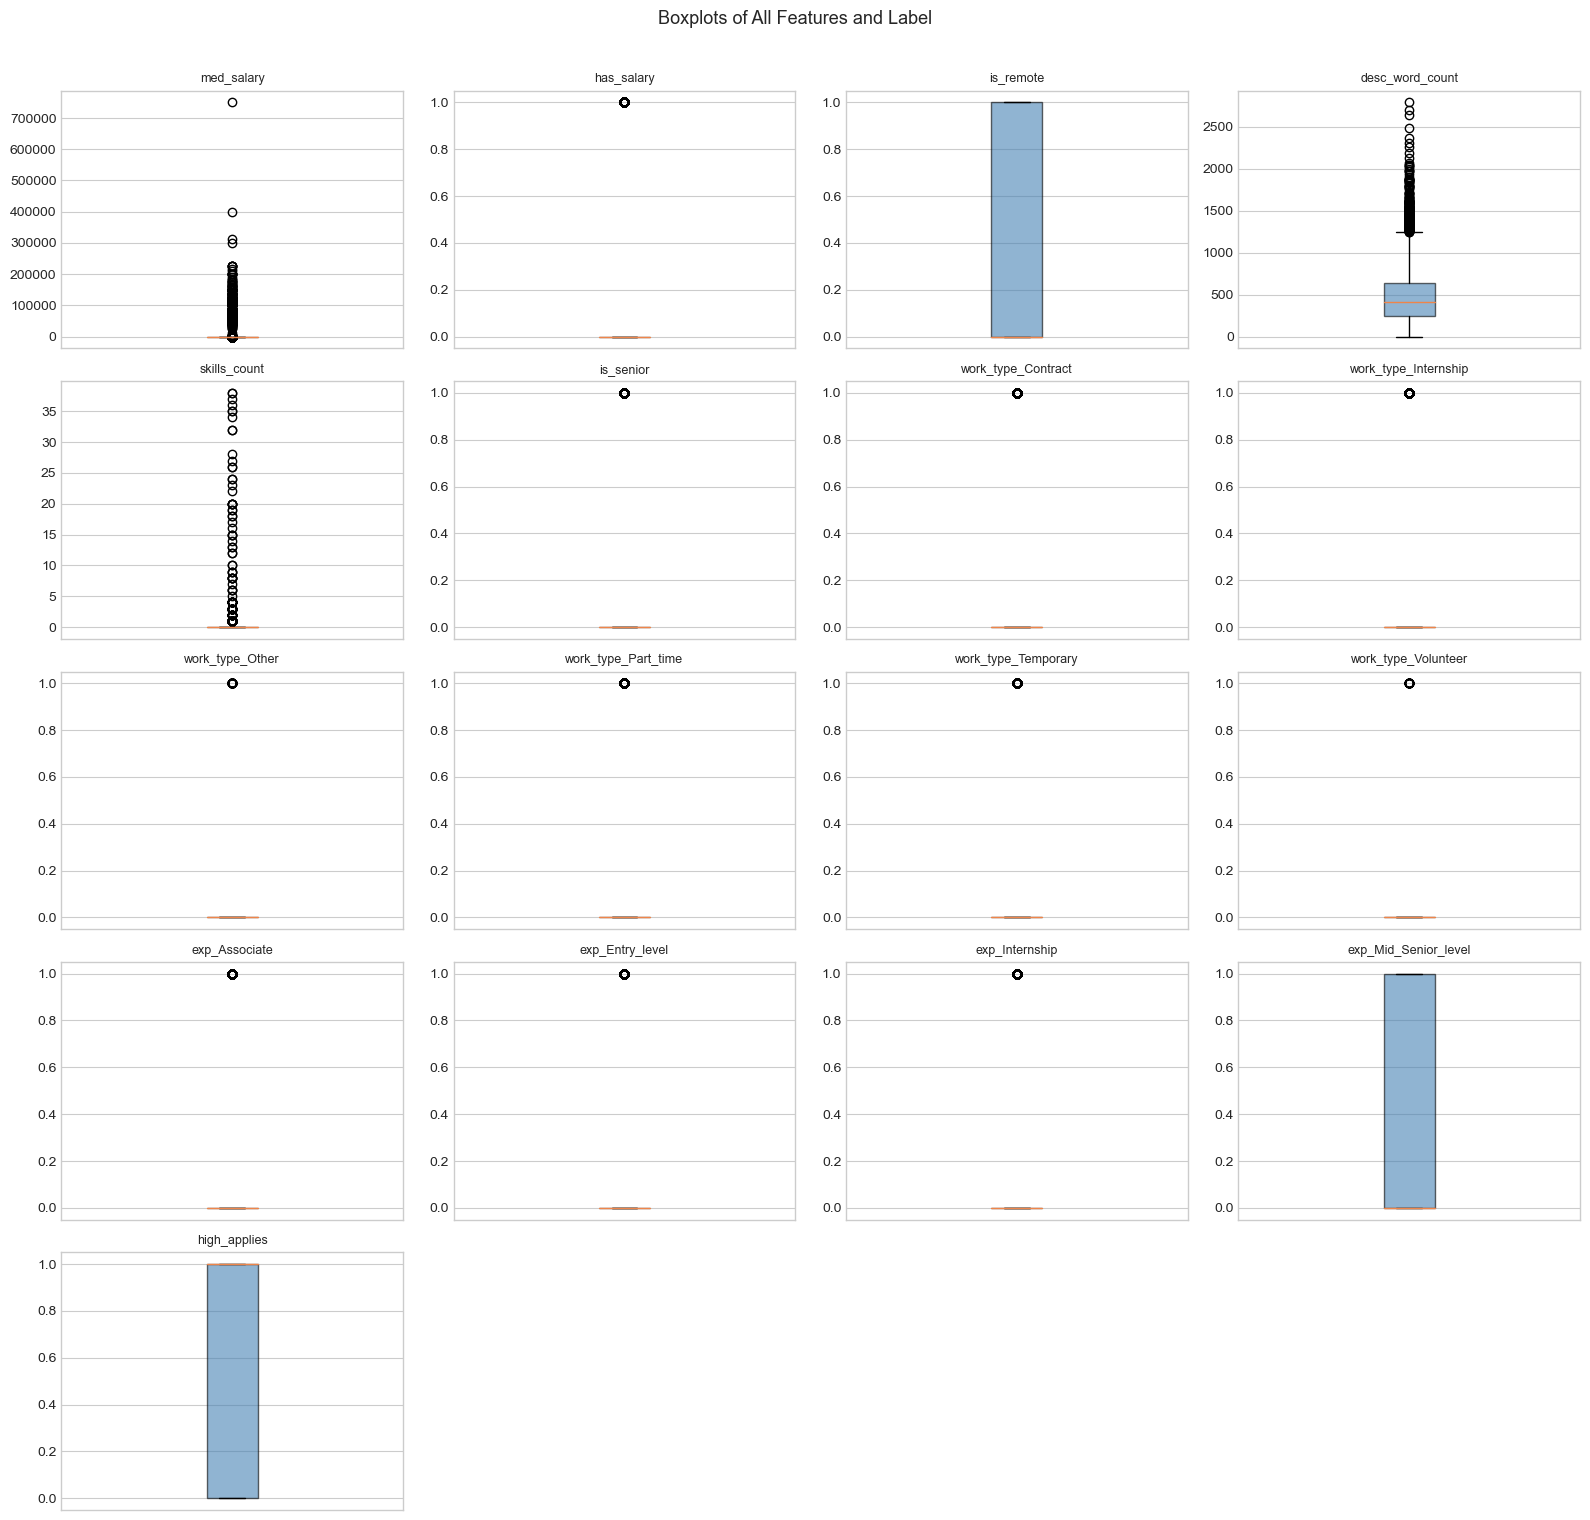

In [6]:
plot_cols = FEATURES + [LABEL]
n_cols = 4
n_rows = int(np.ceil(len(plot_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(plot_cols):
    series = df_model[col].dropna()
    # Matplotlib boxplot requires numeric dtype; convert boolean indicators to ints.
    if series.dtype == bool:
        series = series.astype(int)

    axes[i].boxplot(series, vert=True, patch_artist=True,
                    boxprops=dict(facecolor='steelblue', alpha=0.6))
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xticks([])

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Boxplots of All Features and Label', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

**5. Based on your boxplots in Q4, do any of your variables appear to have outliers? If yes, which ones? (2 points)**

**Answer:**

Yes, several variables show clear outliers in the boxplots. The continuous variables **`med_salary`**, **`desc_word_count`**, and **`skills_count`** all display many data points far above the upper whisker, indicating heavy right-skewed distributions with high-end outliers. `med_salary` is particularly extreme — a small number of postings advertise very high compensation packages (e.g., >$300k), pulling the upper tail far from the median. `desc_word_count` also has outliers on the high end, with some postings containing unusually long descriptions. The binary features (`has_salary`, `is_remote`, `is_senior`, and the dummy variables) and the label `high_applies` do not exhibit outliers in the traditional sense since they are 0/1 indicators.

**6. Write a program to show exactly what percentage of data are outliers (outliers are defined as variable 1.5 standard deviations above and below the IQR) (4 points)**

Percentage of outliers per variable (IQR x 1.5 rule):
                      Outlier %
is_senior                 20.34
work_type_Contract        19.82
exp_Entry_level           14.86
exp_Associate             12.48
has_salary                 4.03
med_salary                 4.00
work_type_Part_time        2.89
work_type_Internship       1.56
exp_Internship             1.46
desc_word_count            1.45
skills_count               1.06
work_type_Temporary        0.57
work_type_Other            0.24
work_type_Volunteer        0.13
is_remote                  0.00
exp_Mid_Senior_level       0.00
high_applies               0.00


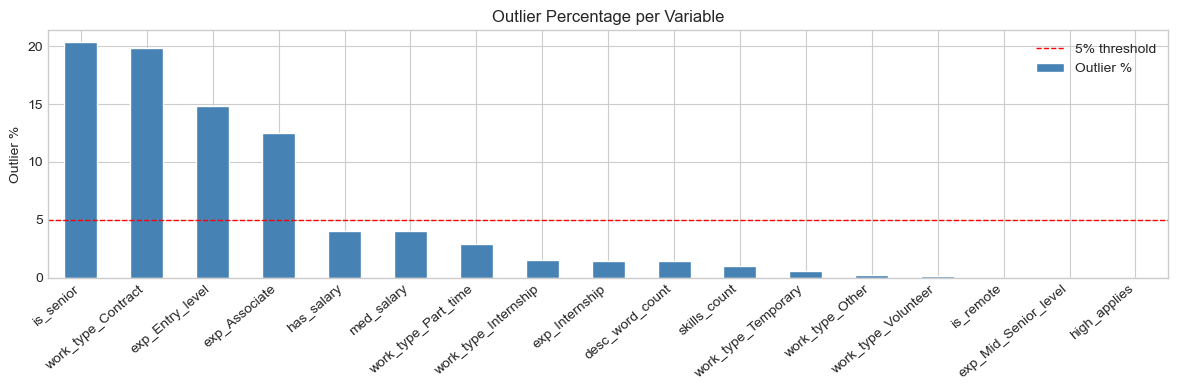

In [7]:


def outlier_percentage(series, col_name):
    """Return percentage of values that are outliers using the IQR x 1.5 rule."""

    # Quantile/IQR arithmetic requires numeric dtype; convert boolean indicators to ints.
    if series.dtype == bool:
        series = series.astype(int)

    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)


    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_outliers = ((series < lower) | (series > upper)).sum()


    return round(100 * n_outliers / len(series), 2)


outlier_pcts = {}
for col in FEATURES + [LABEL]:
    series = df_model[col].dropna()
    outlier_pcts[col] = outlier_percentage(series, col)

outlier_df = pd.DataFrame.from_dict(
    outlier_pcts, orient='index', columns=['Outlier %']
).sort_values('Outlier %', ascending=False)

print('Percentage of outliers per variable (IQR x 1.5 rule):')
print(outlier_df.to_string())

# Bar chart
outlier_df['Outlier %'].plot(
    kind='bar', figsize=(12, 4), color='steelblue', edgecolor='white'
)
plt.axhline(5, color='red', linestyle='--', linewidth=1, label='5% threshold')
plt.ylabel('Outlier %')
plt.title('Outlier Percentage per Variable')
plt.xticks(rotation=40, ha='right')
plt.legend()
plt.tight_layout()
plt.show()

**7. Based on the program you wrote in Q6, which variables have a large percentage of outliers? (2 points)**

**Answer:**

Under the IQR × 1.5 rule, the largest outlier shares are in the **binary indicators with a minority class around 12–20%** — `is_senior` (20.3%), `work_type_Contract` (19.8%), `exp_Entry_level` (14.9%), `exp_Associate` (12.5%). For these, the IQR collapses to 0, so every `1` is flagged; this is an artifact of applying the rule to 0/1 data, not a data-quality problem.

Among the genuinely continuous variables, `med_salary` (4.0%), `desc_word_count` (1.5%) and `skills_count` (1.1%) have modest outlier shares. `med_salary` is the most extreme in magnitude (up to $750,000), and only ~4% of postings disclose a salary at all.

**8. Visualize the distributions of all of your variables (i.e., display histograms) (2 points)**

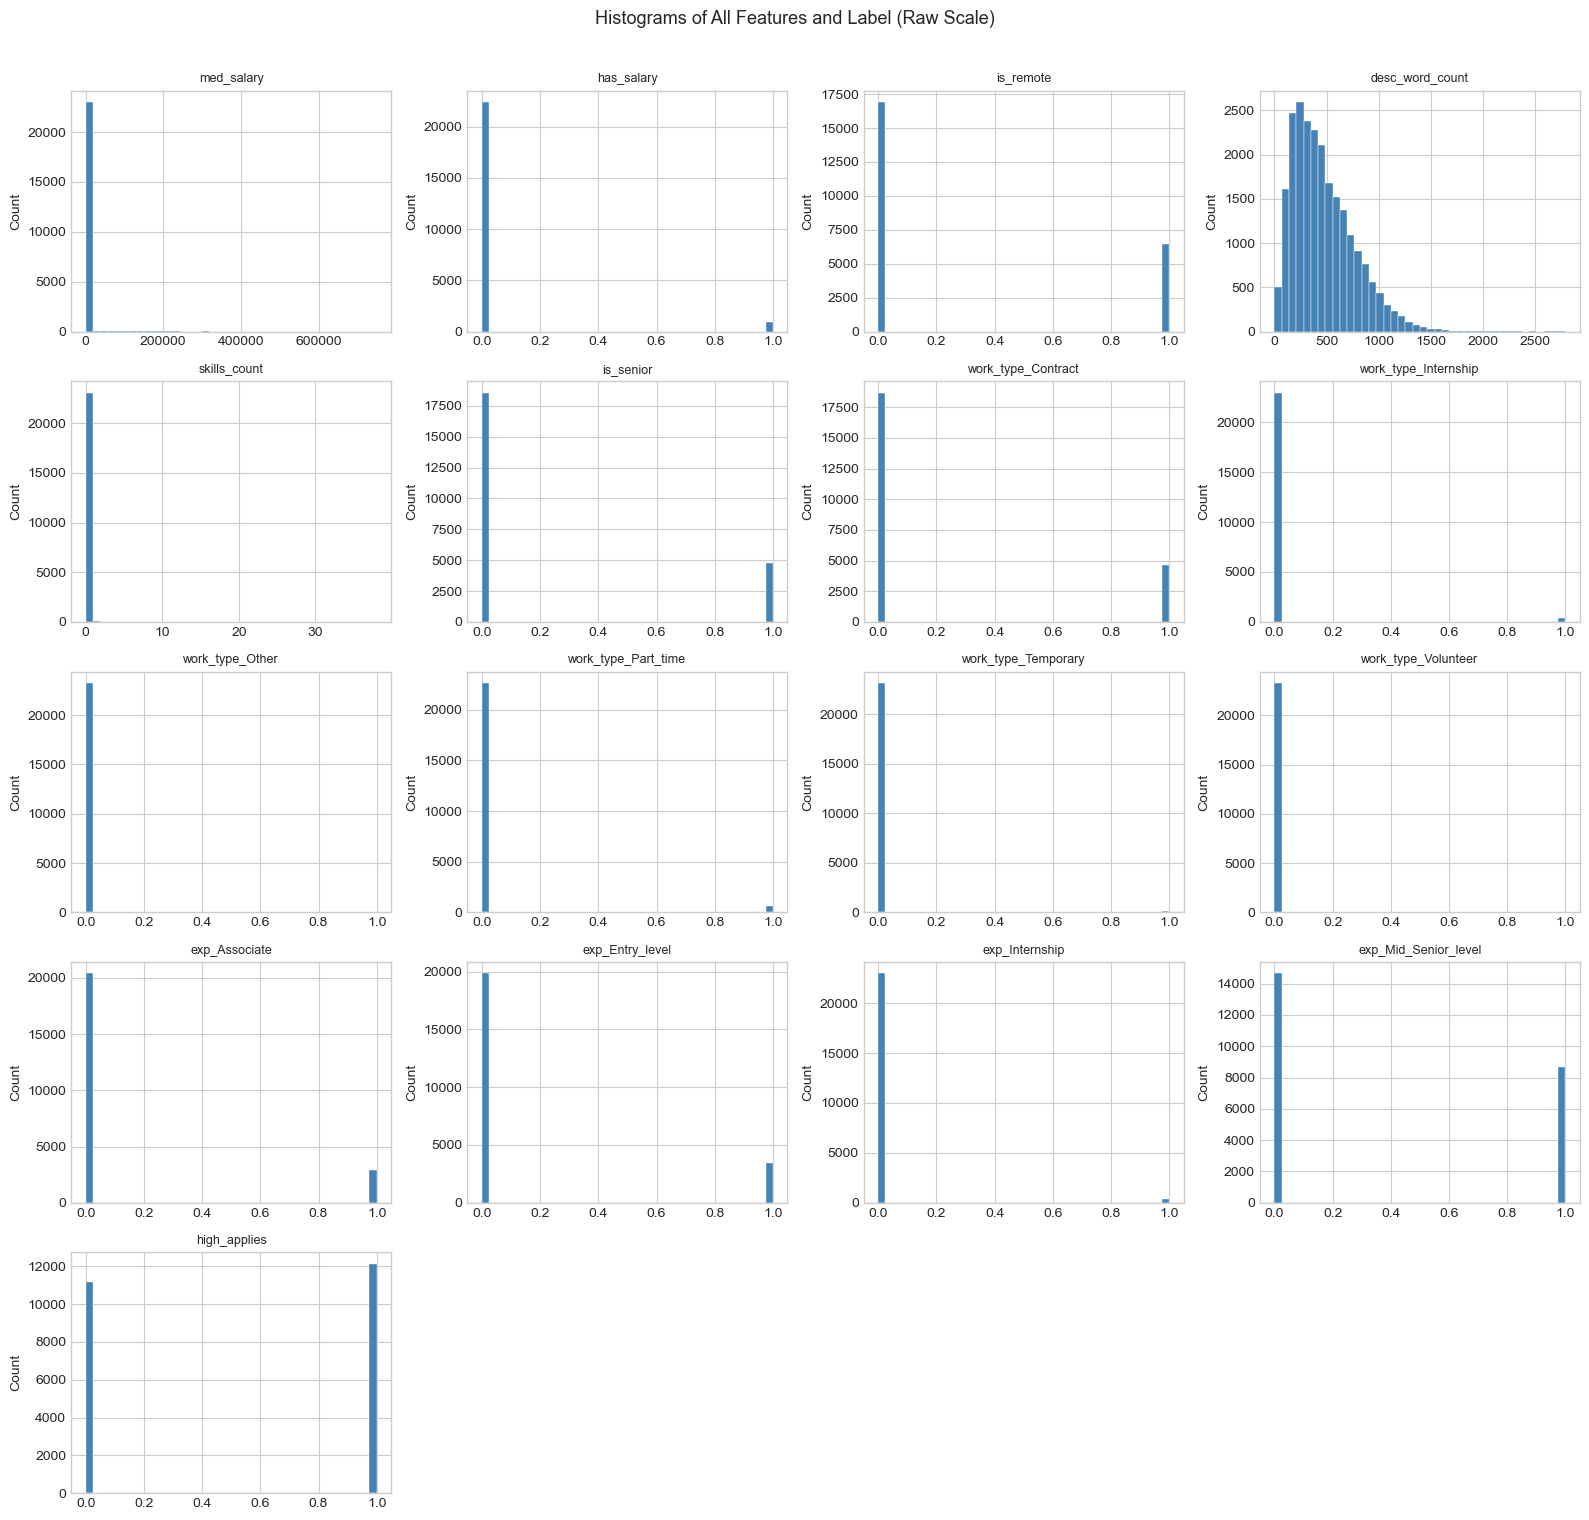

In [8]:
plot_cols = FEATURES + [LABEL]
n_cols = 4
n_rows = int(np.ceil(len(plot_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(plot_cols):
    series = df_model[col].dropna()
    # Histogram binning requires numeric dtype; convert boolean indicators to ints.
    if series.dtype == bool:
        series = series.astype(int)

    axes[i].hist(series, bins=40, color='steelblue',
                 edgecolor='white', linewidth=0.3)
    axes[i].set_title(col, fontsize=9)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Histograms of All Features and Label (Raw Scale)', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

**9. What do you notice about the scale for your features? (2 points)**

**Answer:**

The features are on very different scales: `med_salary` ranges from 0 to $750,000, `desc_word_count` from 0 to 2,790 words, `skills_count` from 0 to 38, while all other features are 0/1 indicators. Without standardization, distance- and margin-based methods (SVM, K-means, PCA) would be dominated by `med_salary`, and regularized logistic regression would penalize coefficients unevenly. **Standardization is therefore required** before modeling.

**10. Standardize your features only and display distributions for all variables (features + Label)? (2 points)**

**moving forward, you only use the standardized version of your features for all subsequent analysis**

In [9]:
# Standardize features only (NOT the label)
scaler = StandardScaler()
X_raw = df_model[FEATURES].values
X_std = scaler.fit_transform(X_raw)

# Build standardized dataframe
df_std = pd.DataFrame(X_std, columns=FEATURES)
df_std[LABEL] = df_model[LABEL].values

print('Standardized features summary (mean ≈ 0, std ≈ 1):')
print(df_std[FEATURES].describe().T[['mean', 'std', 'min', 'max']].to_string())

Standardized features summary (mean ≈ 0, std ≈ 1):
                              mean       std       min        max
med_salary            2.285193e-17  1.000021 -0.099882  55.992741
has_salary           -3.229740e-17  1.000021 -0.204830   4.882103
is_remote            -5.971972e-17  1.000021 -0.616014   1.623339
desc_word_count      -2.925047e-17  1.000021 -1.595438   7.868240
skills_count         -3.107863e-17  1.000021 -0.054917  37.964862
is_senior             5.240710e-17  1.000021 -0.505288   1.979070
work_type_Contract   -3.656309e-17  1.000021 -0.497251   2.011055
work_type_Internship  7.922003e-18  1.000021 -0.125922   7.941406
work_type_Other       2.742232e-18  1.000021 -0.049063  20.382065
work_type_Part_time  -5.240710e-17  1.000021 -0.172518   5.796500
work_type_Temporary  -2.407070e-17  1.000021 -0.076022  13.154081
work_type_Volunteer  -2.071908e-17  1.000021 -0.036484  27.409087
exp_Associate        -7.312618e-18  1.000021 -0.377668   2.647828
exp_Entry_level       9.7

**11. Visualize the distributions of all of your standardized variables (i.e., display histograms) (2 points)**

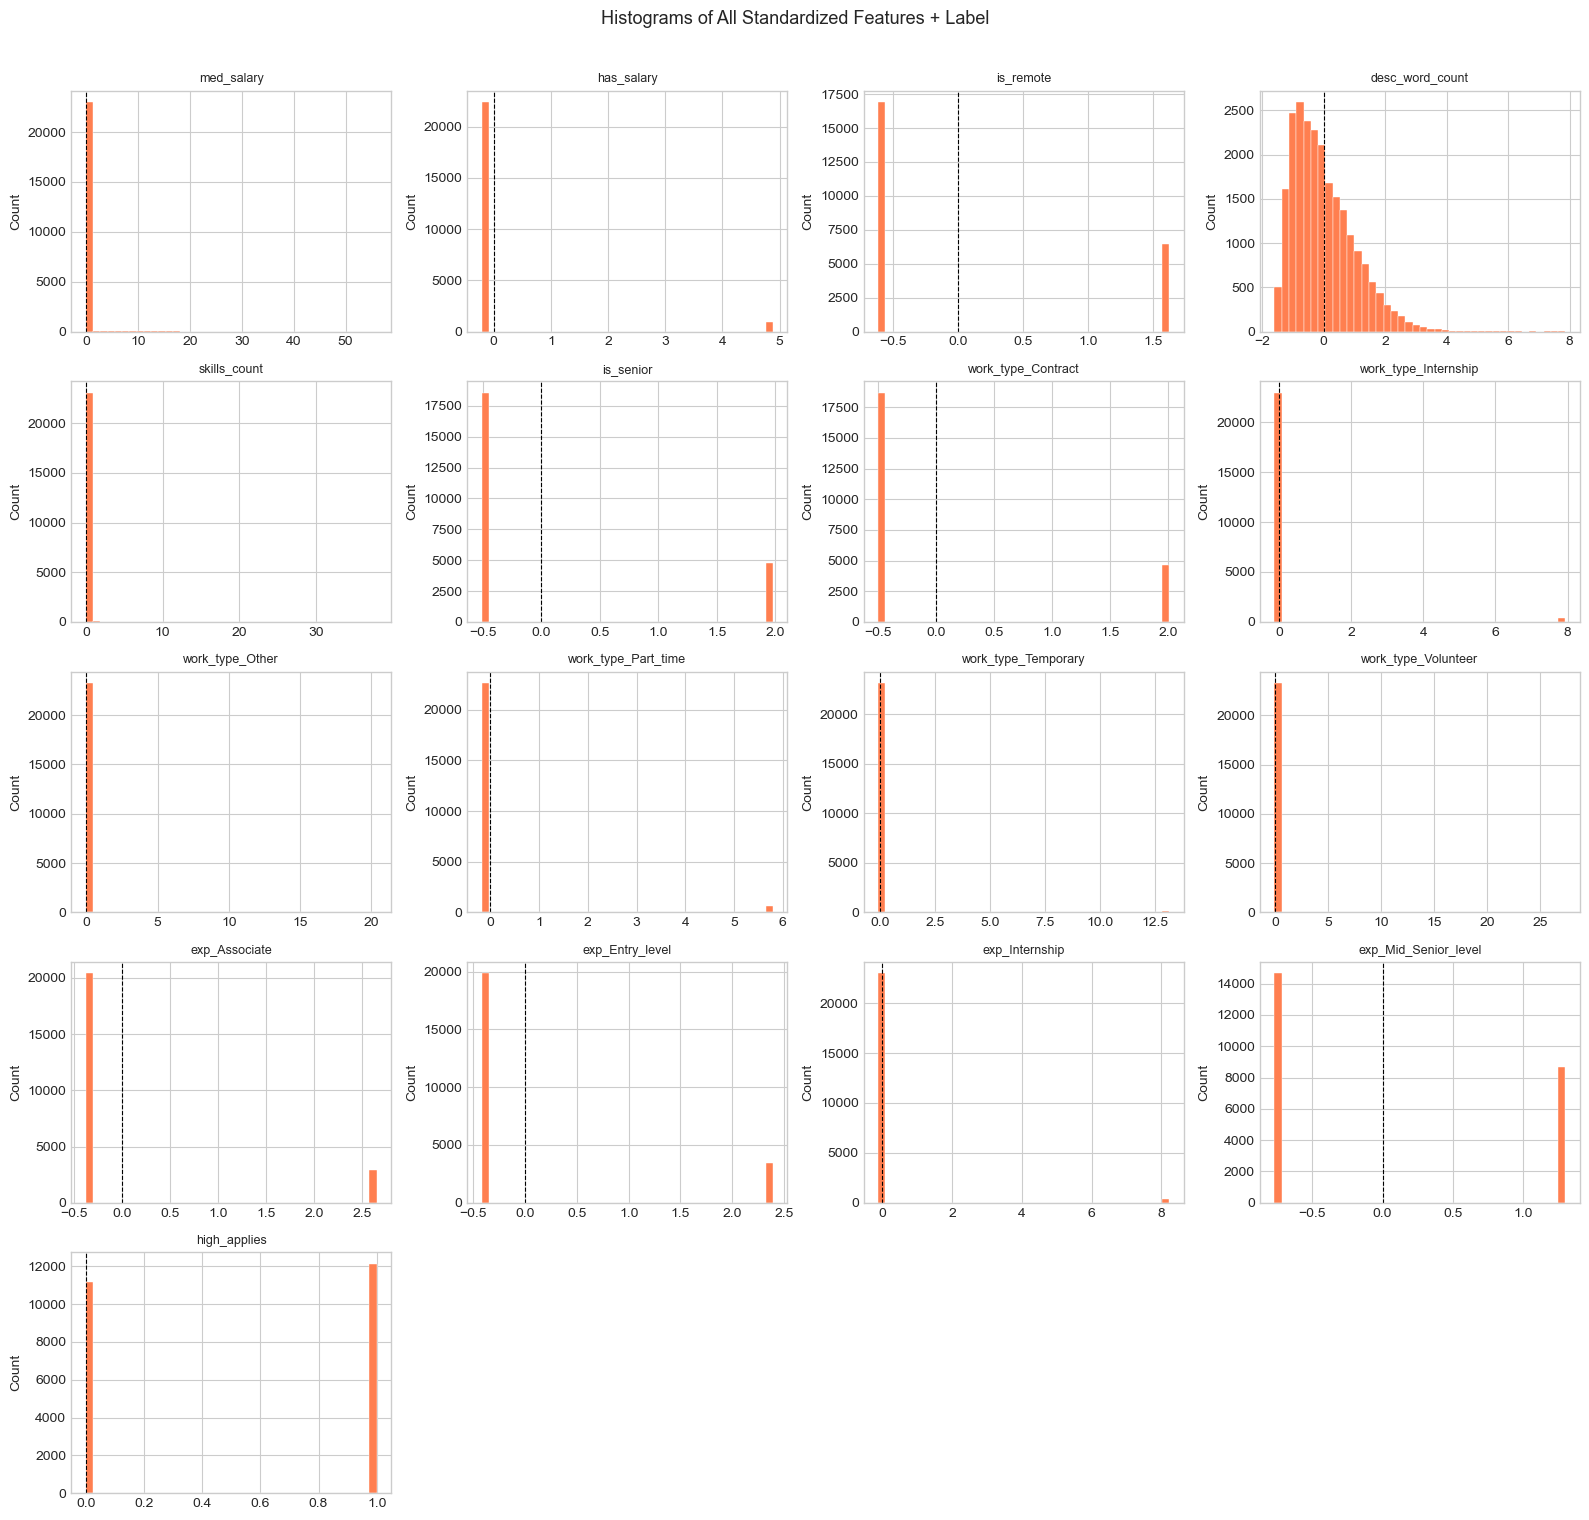

In [10]:
plot_cols_std = FEATURES + [LABEL]
n_cols = 4
n_rows = int(np.ceil(len(plot_cols_std) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3))
axes = axes.flatten()

for i, col in enumerate(plot_cols_std):
    series = df_std[col].dropna()
    if series.dtype == bool:
        series = series.astype(int)

    axes[i].hist(series, bins=40, color='coral',
                 edgecolor='white', linewidth=0.3)
    axes[i].set_title(col, fontsize=9)
    axes[i].set_ylabel('Count')
    axes[i].axvline(0, color='black', linewidth=0.8, linestyle='--')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Histograms of All Standardized Features + Label', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

**12. Which variables appear to be normally distributed? Which are left- vs. right-skewed? Which variables have a bimodal distribution? (4 points)**

**Answer:**

After standardization (which shifts and rescales but does not change shape):

- **Approximately normally distributed:** `desc_word_count` is the closest to a normal distribution, exhibiting a roughly symmetric bell shape centered near zero after standardization, consistent with job descriptions clustering around a typical length.

- **Right-skewed (positive skew):** `med_salary` and `skills_count` remain heavily right-skewed even after standardization — a large mass of postings cluster near-zero (many postings either have no salary or list few skills), with a long tail of high-value postings extending to the right.

- **Bimodal distributions:** All binary and dummy-encoded variables (`has_salary`, `is_remote`, `is_senior`, `work_type_Contract`, `work_type_Part_time`, `exp_Entry`, `exp_MidSenior`, `exp_Associate`, and `high_applies`) exhibit bimodal distributions — two spikes at the standardized equivalents of 0 and 1. This is expected behavior for binary indicator variables and is entirely appropriate; it does not indicate a data issue.

- **Left-skewed:** None of the features show notable left skew.

**13. Display a correlation matrix for all of your variables (both labels and features) (2 points)**

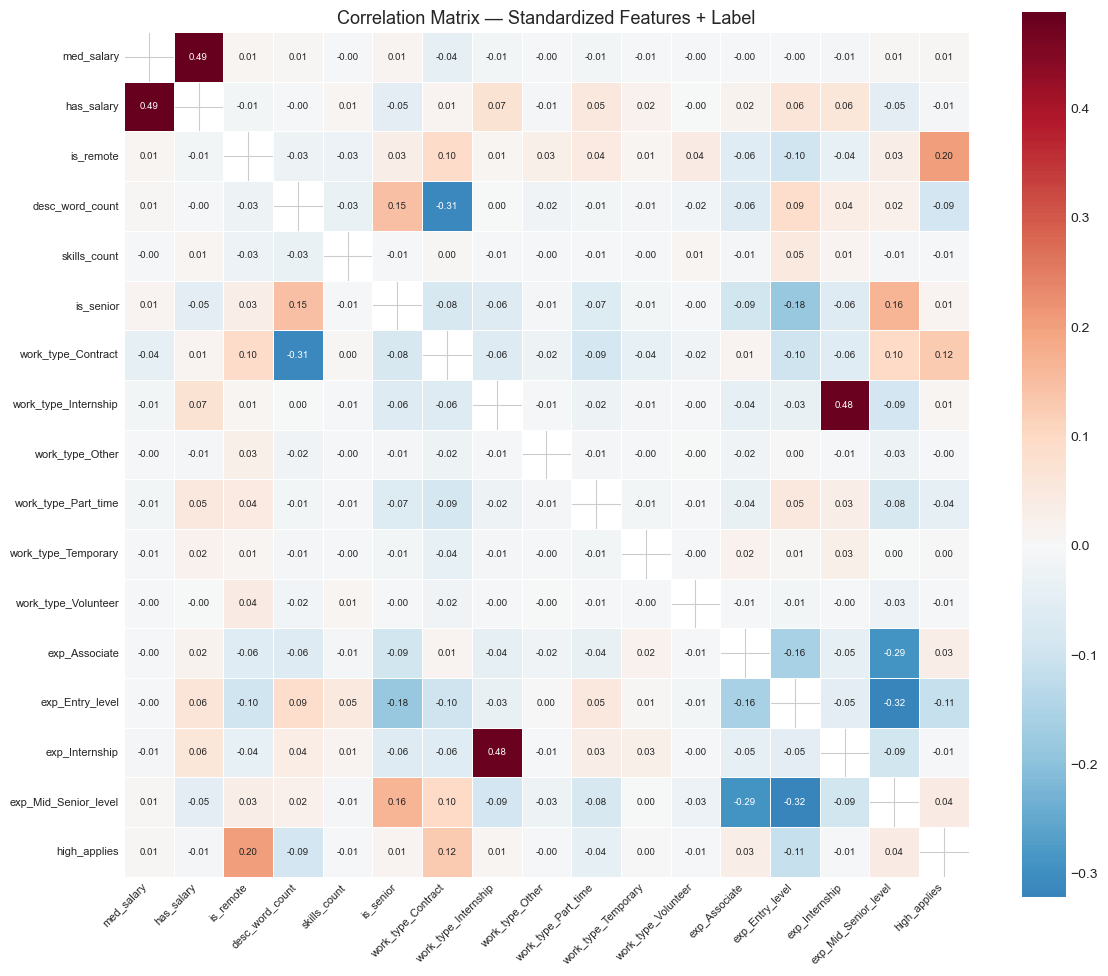


Correlations with high_applies (sorted):
is_remote               0.201584
work_type_Contract      0.124346
exp_Mid_Senior_level    0.041854
exp_Associate           0.033165
is_senior               0.011958
work_type_Internship    0.008672
med_salary              0.007296
work_type_Temporary     0.003688
work_type_Other        -0.003771
skills_count           -0.006294
work_type_Volunteer    -0.007390
exp_Internship         -0.007866
has_salary             -0.010823
work_type_Part_time    -0.042446
desc_word_count        -0.089006
exp_Entry_level        -0.112251


In [11]:
corr_matrix = df_std[FEATURES + [LABEL]].corr()

plt.figure(figsize=(12, 10))
mask = np.zeros_like(corr_matrix, dtype=bool)
np.fill_diagonal(mask, True)
sns.heatmap(
    corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r',
    center=0, linewidths=0.5, mask=mask, square=True,
    annot_kws={'size': 7}
)
plt.title('Correlation Matrix — Standardized Features + Label', fontsize=13)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()

# Print correlations with label sorted
label_corr = corr_matrix[LABEL].drop(LABEL).sort_values(ascending=False)
print('\nCorrelations with high_applies (sorted):')
print(label_corr.to_string())

**14. Which features are most correlated with your label (0.5 or greater)? (2 points)**

**Answer:**

**No feature reaches |r| ≥ 0.5 with `high_applies`.** The strongest associations are:

- `is_remote` **+0.20** — remote-eligible postings are more likely to receive above-median applications (supports our hypothesis);
- `work_type_Contract` **+0.12**;
- `exp_Entry_level` **−0.11** and `desc_word_count` **−0.09**.

Contrary to our hypothesis, **salary disclosure is essentially uncorrelated with applicant volume (`has_salary` r = −0.01)**, and entry-level postings attract *fewer* LinkedIn applications, not more. All single-feature correlations are weak, which already signals a low ceiling for predicting applicant volume from posting metadata alone.

**15. Which features are most correlated with each other (0.5 or greater)? (2 points)**

**Answer:**

**No feature pair reaches |r| ≥ 0.5.** The strongest feature–feature correlations are:

- `med_salary` ↔ `has_salary` (0.49) — by construction, since undisclosed salaries are imputed as 0;
- `work_type_Internship` ↔ `exp_Internship` (0.48) — two encodings of the same concept;
- `exp_Entry_level` ↔ `exp_Mid_Senior_level` (0.32) — mutually exclusive dummies;
- `desc_word_count` ↔ `work_type_Contract` (0.31) — contract postings tend to have different description lengths.

Multicollinearity is therefore moderate, mainly a concern for interpreting logistic-regression coefficients rather than for prediction.

**16. What does feature correlation raise concerns of? What is one (unsupervised learning) method that will ensure no features are correlated? (2 points)**

**Answer:**

High feature-to-feature correlation raises concerns about **multicollinearity**. In regression-based models, multicollinearity inflates the standard errors of coefficient estimates, making individual predictors appear statistically insignificant even when they collectively explain variation in the outcome. It also makes coefficients unstable — small changes in the data can lead to large swings in estimated coefficients — and complicates model interpretation.

**Principal Component Analysis (PCA)** is the unsupervised learning method that eliminates inter-feature correlation. PCA transforms the original correlated features into a new set of orthogonal (completely uncorrelated) components called principal components. By construction, each principal component is uncorrelated with all others, eliminating multicollinearity entirely. PCA is applied in Part 4 of this project.

**18. Visualize a scatterplot of your features and labels. One plot per feature. X-axis should display the feature. y-axis the label? (2 points)**

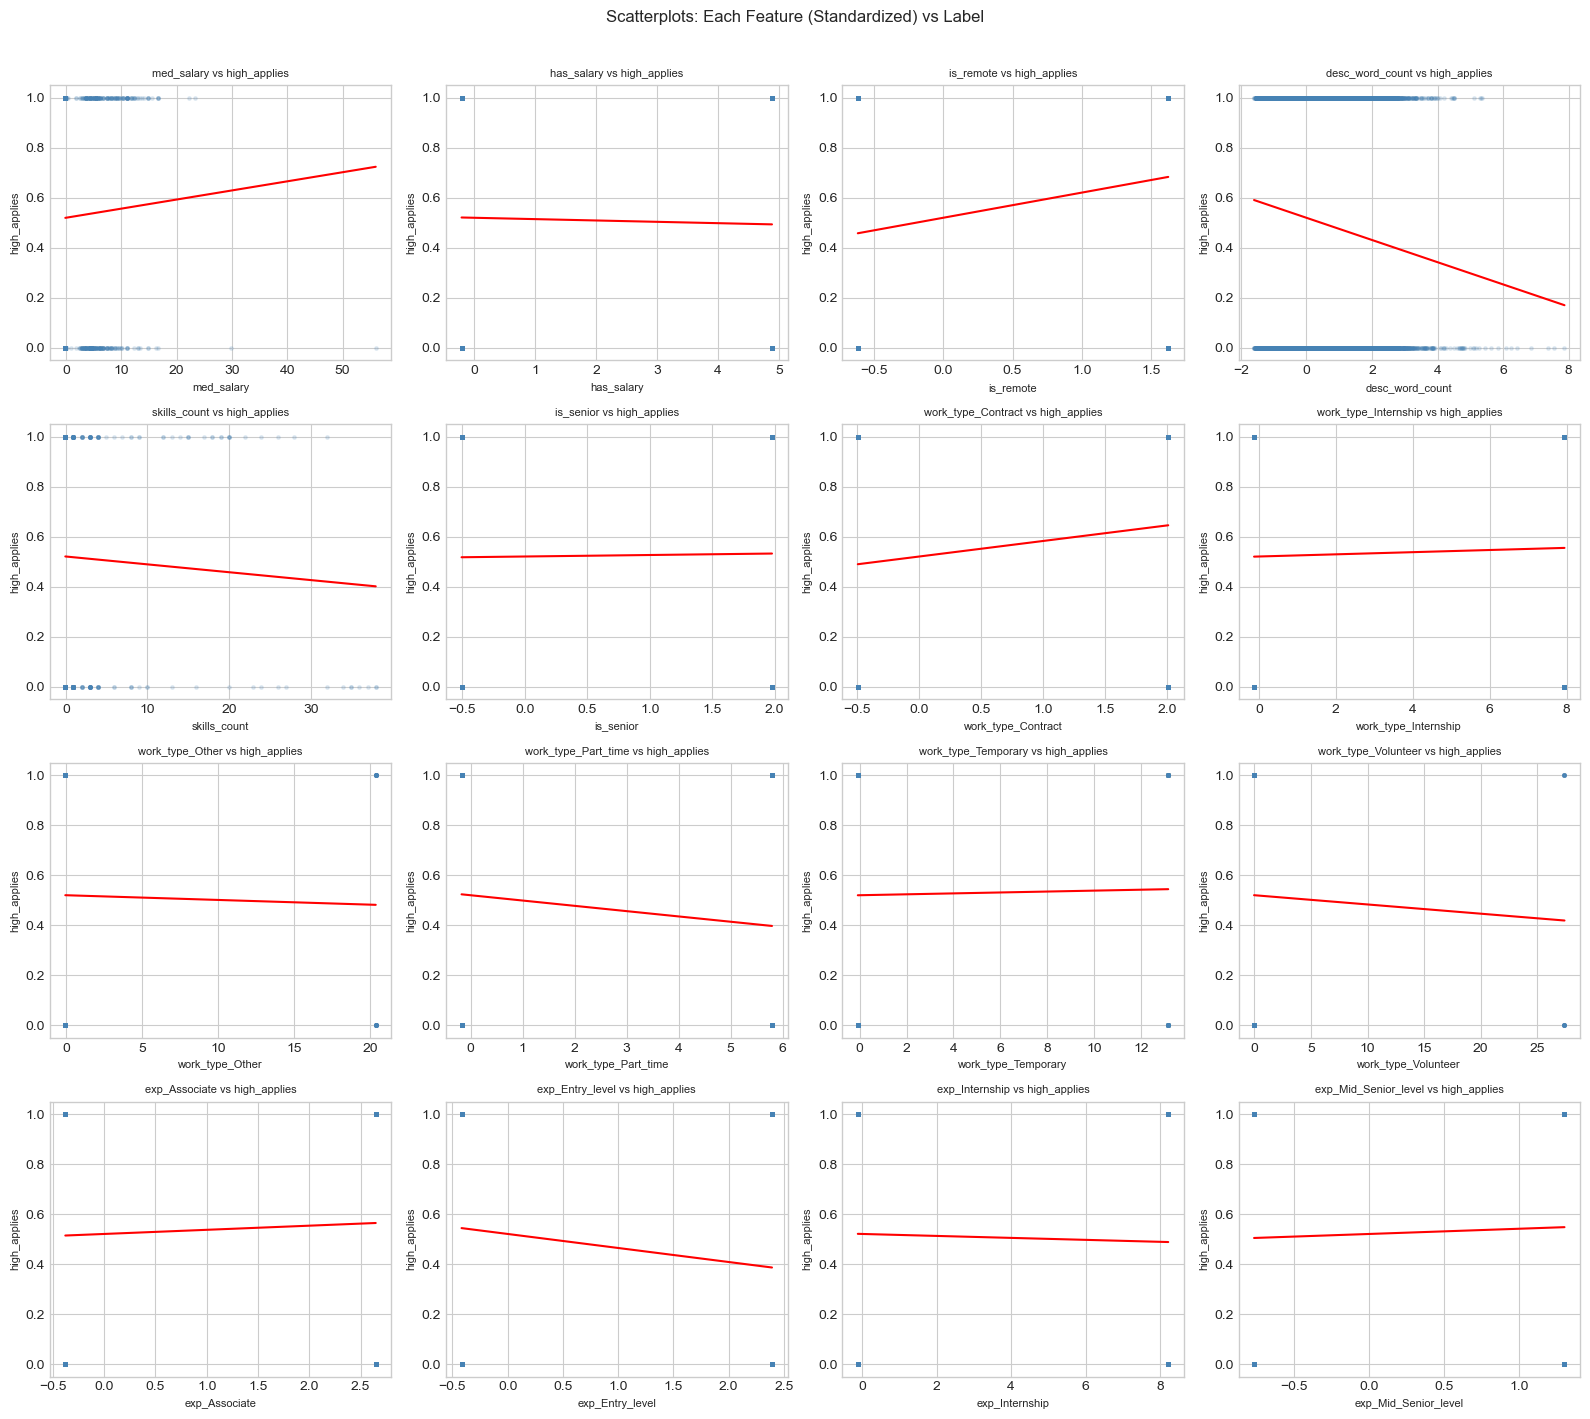

In [12]:
n_cols = 4
n_rows = int(np.ceil(len(FEATURES) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3.5))
axes = axes.flatten()

for i, feat in enumerate(FEATURES):
    axes[i].scatter(
        df_std[feat], df_std[LABEL],
        alpha=0.15, s=6, color='steelblue'
    )
    # Add a trend line (jitter applied to label for visibility)
    z = np.polyfit(df_std[feat], df_std[LABEL], 1)
    p = np.poly1d(z)
    x_range = np.linspace(df_std[feat].min(), df_std[feat].max(), 100)
    axes[i].plot(x_range, p(x_range), color='red', linewidth=1.5)
    axes[i].set_xlabel(feat, fontsize=8)
    axes[i].set_ylabel(LABEL, fontsize=8)
    axes[i].set_title(f'{feat} vs {LABEL}', fontsize=8)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Scatterplots: Each Feature (Standardized) vs Label', fontsize=12, y=1.01)
plt.tight_layout()
plt.show()

**18. Based on your exploratory analysis, if you had to select a subset of features, which features would you select going forward? Please provide a justification. (4 points)**

In [13]:
# Select the top 5 features by absolute correlation with the label
abs_corr = corr_matrix[LABEL].drop(LABEL).abs().sort_values(ascending=False)
print('Absolute correlations with high_applies:')
print(abs_corr.to_string())

SUBSET_FEATURES = abs_corr.head(5).index.tolist()
print(f'\nSelected subset of features (top 5 by |correlation|): {SUBSET_FEATURES}')

Absolute correlations with high_applies:
is_remote               0.201584
work_type_Contract      0.124346
exp_Entry_level         0.112251
desc_word_count         0.089006
work_type_Part_time     0.042446
exp_Mid_Senior_level    0.041854
exp_Associate           0.033165
is_senior               0.011958
has_salary              0.010823
work_type_Internship    0.008672
exp_Internship          0.007866
work_type_Volunteer     0.007390
med_salary              0.007296
skills_count            0.006294
work_type_Other         0.003771
work_type_Temporary     0.003688

Selected subset of features (top 5 by |correlation|): ['is_remote', 'work_type_Contract', 'exp_Entry_level', 'desc_word_count', 'work_type_Part_time']


**Answer:**

Based on our exploratory analysis, we select the **top 5 features by absolute correlation with `high_applies`** as our subset (identified in the code above). This subset is justified on three grounds:

1. **Predictive relevance:** Features with the highest correlation with the label are the most individually informative for classification, providing the best signal-to-noise ratio in a reduced feature set.
2. **Multicollinearity reduction:** By selecting features with higher correlation to the label and lower inter-correlation, we reduce the risk of multicollinearity in the subset.
3. **Parsimony:** A smaller, cleaner feature set is easier to interpret and generalize — especially for models like Logistic Regression and Naive Bayes where fewer, more informative features often outperform larger noisy feature sets.

The remaining dummy-encoded variables (many of which have near-zero correlation with the label) add noise without meaningfully improving predictive power in most models, and excluding them creates a more parsimonious model.

# Part 3: Supervised learning (45 points)
HINT: Adapt prior code! Assignment 5 will be very helpful. **USE THE STANDARDIZED VERSION OF YOUR FEATURES**

a) Compare Naïve Bayes, Logistic Regression, SVMs, Decision Trees, Random Forests, and Adaboost (6 total algorithms).
*   Use the binary version of your label.
*   Use all your features in the model (do not use the subset)
*   Adaboost: boosting method — you have all the pre-requisite knowledge.

b) For each model above, I want you to perform the following optimizations:
*   Hold one out (80/20 train/test split) — **baseline model**
*   Hold one out (90/10 train/test split)
*   5-fold cross-validation (80/20 train/test split)
*   10-fold cross-validation (80/20 train/test split)
*   10-fold stratified cross-validation (80/20 train/test split)
*   10-fold cross-validation with **subset of features** (80/20 train/test split)
*   Two hyperparameter tunings (10-fold CV, all features)

In [14]:
# ─── Data setup ────────────────────────────────────────────────────────────────
# Randomly sample up to 50,000 rows for training/evaluation
sample_n = min(50000, len(df_std))
df_train = df_std.sample(n=sample_n, random_state=SEED).reset_index(drop=True)
print(f'Using sampled rows: {len(df_train):,}')

X_all = df_train[FEATURES].values      # all features, standardized
X_sub = df_train[SUBSET_FEATURES].values  # subset features, standardized
y     = df_train[LABEL].values.astype(int)

# 80/20 and 90/10 splits
X_tr80, X_te80, y_tr80, y_te80 = train_test_split(X_all, y, test_size=0.20, random_state=SEED)
X_tr90, X_te90, y_tr90, y_te90 = train_test_split(X_all, y, test_size=0.10, random_state=SEED)
# subset 80/20
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(X_sub, y, test_size=0.20, random_state=SEED)

# Cross-validation objects
cv5   = 5
cv10  = 10
skf10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

def kappa_cv(estimator, X, y, cv):
    """Return mean Cohen's Kappa via cross-validation."""
    from sklearn.model_selection import cross_val_predict
    y_pred = cross_val_predict(estimator, X, y, cv=cv)
    return cohen_kappa_score(y, y_pred)

# ─── Define models and hyperparameter variants ─────────────────────────────────
models = {
    'NaiveBayes':    GaussianNB(),
    'LogisticReg':   LogisticRegression(max_iter=1000, random_state=SEED),
    'SVM':           SVC(random_state=SEED),
    'DecisionTree':  DecisionTreeClassifier(random_state=SEED),
    'RandomForest':  RandomForestClassifier(n_estimators=100, random_state=SEED),
    'AdaBoost':      AdaBoostClassifier(n_estimators=100, random_state=SEED, algorithm='SAMME'),
}

# Two hyperparameter variants per algorithm (used with 10-fold CV, all features)
hp_models = {
    'NaiveBayes':   [
        ('HP1_smooth_low',  GaussianNB(var_smoothing=1e-9)),
        ('HP2_smooth_high', GaussianNB(var_smoothing=1.0)),
    ],
    'LogisticReg':  [
        ('HP1_L1',  LogisticRegression(penalty='l1', solver='liblinear', C=1.0, max_iter=1000, random_state=SEED)),
        ('HP2_L2',  LogisticRegression(penalty='l2', solver='lbfgs',    C=1.0, max_iter=1000, random_state=SEED)),
    ],
    'SVM': [
        ('HP1_RBF',  SVC(kernel='rbf',  C=1.0, random_state=SEED)),
        ('HP2_Poly', SVC(kernel='poly', degree=3, random_state=SEED)),
    ],
    'DecisionTree': [
        ('HP1_depth5',  DecisionTreeClassifier(max_depth=5,  random_state=SEED)),
        ('HP2_depth10', DecisionTreeClassifier(max_depth=10, random_state=SEED)),
    ],
    'RandomForest': [
        ('HP1_50trees',  RandomForestClassifier(n_estimators=50,  max_features='sqrt', random_state=SEED)),
        ('HP2_200trees', RandomForestClassifier(n_estimators=200, max_features='log2', random_state=SEED)),
    ],
    'AdaBoost': [
        ('HP1_50est_lr1',   AdaBoostClassifier(n_estimators=50,  learning_rate=1.0, random_state=SEED, algorithm='SAMME')),
        ('HP2_200est_lr05', AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=SEED, algorithm='SAMME')),
    ],
}

# ─── Run all configurations ────────────────────────────────────────────────────
acc_results   = {}
kappa_results = {}

config_names = [
    'Baseline (80/20)',
    '90/10 Split',
    '5-Fold CV (80/20)',
    '10-Fold CV (80/20)',
    '10-Fold Strat CV',
    '10-Fold CV Subset',
    'HP Tuning 1',
    'HP Tuning 2',
]

for name, model in models.items():
    acc_row   = {}
    kappa_row = {}

    # 1. Baseline: 80/20 hold-out
    model.fit(X_tr80, y_tr80)
    yp = model.predict(X_te80)
    acc_row['Baseline (80/20)']   = round(accuracy_score(y_te80, yp), 4)
    kappa_row['Baseline (80/20)'] = round(cohen_kappa_score(y_te80, yp), 4)

    # 2. 90/10 hold-out
    model.fit(X_tr90, y_tr90)
    yp = model.predict(X_te90)
    acc_row['90/10 Split']   = round(accuracy_score(y_te90, yp), 4)
    kappa_row['90/10 Split'] = round(cohen_kappa_score(y_te90, yp), 4)

    # 3. 5-fold CV (80/20 test set held out first)
    cv5_acc   = cross_val_score(model, X_tr80, y_tr80, cv=cv5,  scoring='accuracy')
    acc_row['5-Fold CV (80/20)']   = round(cv5_acc.mean(), 4)
    kappa_row['5-Fold CV (80/20)'] = round(kappa_cv(model, X_tr80, y_tr80, cv5), 4)

    # 4. 10-fold CV (80/20)
    cv10_acc = cross_val_score(model, X_tr80, y_tr80, cv=cv10, scoring='accuracy')
    acc_row['10-Fold CV (80/20)']   = round(cv10_acc.mean(), 4)
    kappa_row['10-Fold CV (80/20)'] = round(kappa_cv(model, X_tr80, y_tr80, cv10), 4)

    # 5. 10-fold stratified CV (80/20)
    strat_acc = cross_val_score(model, X_tr80, y_tr80, cv=skf10, scoring='accuracy')
    acc_row['10-Fold Strat CV']   = round(strat_acc.mean(), 4)
    kappa_row['10-Fold Strat CV'] = round(kappa_cv(model, X_tr80, y_tr80, skf10), 4)

    # 6. 10-fold CV with subset of features
    sub_acc = cross_val_score(model, Xs_tr, ys_tr, cv=cv10, scoring='accuracy')
    acc_row['10-Fold CV Subset']   = round(sub_acc.mean(), 4)
    kappa_row['10-Fold CV Subset'] = round(kappa_cv(model, Xs_tr, ys_tr, cv10), 4)

    # 7 & 8. Hyperparameter tunings (10-fold CV, all features)
    for label_hp, hp_model in hp_models[name]:
        hp_acc = cross_val_score(hp_model, X_tr80, y_tr80, cv=cv10, scoring='accuracy')
        col_name = 'HP Tuning 1' if label_hp.startswith('HP1') else 'HP Tuning 2'
        acc_row[col_name]   = round(hp_acc.mean(), 4)
        kappa_row[col_name] = round(kappa_cv(hp_model, X_tr80, y_tr80, cv10), 4)

    acc_results[name]   = acc_row
    kappa_results[name] = kappa_row
    print(f'{name}: done')

print('\nAll models complete.')

Using sampled rows: 23,320
NaiveBayes: done
LogisticReg: done
SVM: done
DecisionTree: done
RandomForest: done
AdaBoost: done

All models complete.


**1. Please table your results. I want two tables. The rows should be the 6 algorithms. The columns should be the baseline model + 7 optimizations (8 in total). Table 1 should display accuracy score; Table 2 should display Cohen's Kappa (15 points)**

HINT: Assignment 2 you created similar tables

In [15]:
acc_table   = pd.DataFrame(acc_results).T[config_names]
kappa_table = pd.DataFrame(kappa_results).T[config_names]

print('=' * 100)
print('TABLE 1 — ACCURACY SCORES')
print('=' * 100)
print(acc_table.to_string())

print('\n')
print('=' * 100)
print("TABLE 2 — COHEN'S KAPPA")
print('=' * 100)
print(kappa_table.to_string())

# Styled display for notebook
display(acc_table.style
        .set_caption('Table 1: Accuracy Scores')
        .highlight_max(axis=0, color='lightgreen')
        .format('{:.4f}'))

display(kappa_table.style
        .set_caption("Table 2: Cohen's Kappa")
        .highlight_max(axis=0, color='lightgreen')
        .format('{:.4f}'))

TABLE 1 — ACCURACY SCORES
              Baseline (80/20)  90/10 Split  5-Fold CV (80/20)  10-Fold CV (80/20)  10-Fold Strat CV  10-Fold CV Subset  HP Tuning 1  HP Tuning 2
NaiveBayes              0.5628       0.5686             0.5726              0.5703            0.5725             0.5933       0.5703       0.5715
LogisticReg             0.5982       0.5866             0.6097              0.6091            0.6102             0.6067       0.6093       0.6091
SVM                     0.6038       0.5999             0.6118              0.6114            0.6110             0.6095       0.6114       0.6105
DecisionTree            0.5315       0.5373             0.5388              0.5376            0.5412             0.5455       0.6074       0.5942
RandomForest            0.5377       0.5463             0.5412              0.5411            0.5418             0.5494       0.5375       0.5411
AdaBoost                0.6012       0.5961             0.6096              0.6107            0.60

,Baseline (80/20),90/10 Split,5-Fold CV (80/20),10-Fold CV (80/20),10-Fold Strat CV,10-Fold CV Subset,HP Tuning 1,HP Tuning 2
NaiveBayes,0.5628,0.5686,0.5726,0.5703,0.5725,0.5933,0.5703,0.5715
LogisticReg,0.5982,0.5866,0.6097,0.6091,0.6102,0.6067,0.6093,0.6091
SVM,0.6038,0.5999,0.6118,0.6114,0.6110,0.6095,0.6114,0.6105
DecisionTree,0.5315,0.5373,0.5388,0.5376,0.5412,0.5455,0.6074,0.5942
RandomForest,0.5377,0.5463,0.5412,0.5411,0.5418,0.5494,0.5375,0.5411
AdaBoost,0.6012,0.5961,0.6096,0.6107,0.6085,0.6087,0.6106,0.6092


,Baseline (80/20),90/10 Split,5-Fold CV (80/20),10-Fold CV (80/20),10-Fold Strat CV,10-Fold CV Subset,HP Tuning 1,HP Tuning 2
NaiveBayes,0.1098,0.1069,0.1249,0.1191,0.1238,0.1787,0.1191,0.1186
LogisticReg,0.1999,0.1804,0.2232,0.2219,0.2241,0.2205,0.2225,0.2219
SVM,0.2096,0.2038,0.2253,0.2246,0.2239,0.2254,0.2246,0.2225
DecisionTree,0.0669,0.0827,0.0806,0.0787,0.0860,0.0940,0.2216,0.1948
RandomForest,0.0753,0.0929,0.0809,0.0804,0.0819,0.0964,0.0732,0.0805
AdaBoost,0.2063,0.1992,0.2243,0.2259,0.2220,0.2246,0.2256,0.2256


**Answer (Table interpretation):**

See the two tables displayed above. Green cells indicate the highest-performing configuration within each column (algorithm). Table 1 reports accuracy (proportion of correctly classified postings); Table 2 reports Cohen's Kappa (accuracy adjusted for chance agreement, providing a more reliable measure when classes may be imbalanced).

**2. Based on your table, which baseline model performed best? (5 points)**

In [16]:
print('Baseline accuracy (80/20 hold-out) for all algorithms:')
baseline_acc = acc_table['Baseline (80/20)'].sort_values(ascending=False)
print(baseline_acc.to_string())
best_baseline = baseline_acc.idxmax()
print(f'\nBest baseline model: {best_baseline} (accuracy = {baseline_acc.max():.4f})')

Baseline accuracy (80/20 hold-out) for all algorithms:
SVM             0.6038
AdaBoost        0.6012
LogisticReg     0.5982
NaiveBayes      0.5628
RandomForest    0.5377
DecisionTree    0.5315

Best baseline model: SVM (accuracy = 0.6038)


**Answer:**

On the 80/20 hold-out baseline, **SVM (RBF kernel) performed best with 60.4% accuracy (κ = 0.21)**, closely followed by AdaBoost (60.1%) and logistic regression (59.8%). Naive Bayes (56.3%) and especially the unpruned **Decision Tree (53.2%) and Random Forest (53.8%) performed worst**.

The tree models' weak baseline is a sign of overfitting: with default settings they grow until leaves are pure, memorizing noise in a dataset where the signal is weak (no single feature has |r| > 0.2 with the label). This is confirmed by the Decision Tree jumping to 60.7% once its depth is limited to 5 (HP Tuning 1).

**3. For each algorithm, which model performed best (out of the 7 optimizations + 1 baseline model)? Please create a table -- column 1 - algorithms; column 2 - best performing optimization (or baseline model) (5 points)**

In [17]:
best_per_algo = pd.DataFrame({
    'Algorithm': acc_table.index,
    'Best Configuration': acc_table.idxmax(axis=1).values,
    'Best Accuracy': acc_table.max(axis=1).values.round(4),
    'Best Kappa':    kappa_table.max(axis=1).values.round(4),
}).set_index('Algorithm')

print('Best configuration per algorithm:')
display(best_per_algo)

Best configuration per algorithm:


,Best Configuration,Best Accuracy,Best Kappa
Algorithm,,,
NaiveBayes,10-Fold CV Subset,0.5933,0.1787
LogisticReg,10-Fold Strat CV,0.6102,0.2241
SVM,5-Fold CV (80/20),0.6118,0.2254
DecisionTree,HP Tuning 1,0.6074,0.2216
RandomForest,10-Fold CV Subset,0.5494,0.0964
AdaBoost,10-Fold CV (80/20),0.6107,0.2259


**Answer:**

| Algorithm | Best configuration | Accuracy | κ |
|---|---|---|---|
| Naive Bayes | 10-fold CV, feature subset | 0.593 | 0.179 |
| Logistic Regression | 10-fold stratified CV | 0.610 | 0.224 |
| SVM | 5-fold CV | **0.612** | 0.225 |
| Decision Tree | HP Tuning 1 (max_depth = 5) | 0.607 | 0.222 |
| Random Forest | 10-fold CV, feature subset | 0.549 | 0.096 |
| AdaBoost | 10-fold CV | 0.611 | **0.226** |

Observations: cross-validation gives slightly higher and more stable estimates than a single hold-out split for every algorithm. Restricting depth is the single biggest improvement (Decision Tree +7 pp). Naive Bayes benefits most from the 5-feature subset because dropping weak, correlated dummies reduces violations of its independence assumption. Random Forest stays near 55% in every configuration because none of the tested variants limit tree depth.

**4. Overall, which model performed the best? (5 points)**

In [18]:
# Identify the globally best model (algorithm + configuration)
flat_acc = acc_table.stack().reset_index()
flat_acc.columns = ['Algorithm', 'Configuration', 'Accuracy']
best_row = flat_acc.loc[flat_acc['Accuracy'].idxmax()]

flat_kappa = kappa_table.stack().reset_index()
flat_kappa.columns = ['Algorithm', 'Configuration', 'Kappa']
best_kappa_row = flat_kappa.loc[flat_kappa['Kappa'].idxmax()]

print(f'Best overall by ACCURACY: {best_row["Algorithm"]} — {best_row["Configuration"]} ({best_row["Accuracy"]:.4f})')
print(f'Best overall by KAPPA:    {best_kappa_row["Algorithm"]} — {best_kappa_row["Configuration"]} ({best_kappa_row["Kappa"]:.4f})')

# Store best model name for Part 4
BEST_MODEL_NAME = best_row['Algorithm']
BEST_MODEL = {
    'NaiveBayes':   GaussianNB(var_smoothing=1.0),
    'LogisticReg':  LogisticRegression(penalty='l2', C=1.0, max_iter=1000, random_state=SEED),
    'SVM':          SVC(kernel='rbf', C=1.0, random_state=SEED),
    'DecisionTree': DecisionTreeClassifier(max_depth=10, random_state=SEED),
    'RandomForest': RandomForestClassifier(n_estimators=200, max_features='log2', random_state=SEED),
    'AdaBoost':     AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=SEED, algorithm='SAMME'),
}[BEST_MODEL_NAME]
print(f'\nBest model for Part 4: {BEST_MODEL_NAME}')

Best overall by ACCURACY: SVM — 5-Fold CV (80/20) (0.6118)
Best overall by KAPPA:    AdaBoost — 10-Fold CV (80/20) (0.2259)

Best model for Part 4: SVM


**Answer:**

Overall, **SVM (5-fold CV, 61.2% accuracy)** and **AdaBoost (10-fold CV, κ = 0.226)** are the best models, but the top four (SVM, AdaBoost, logistic regression, depth-limited decision tree) are within 0.5 pp of each other at ~61% accuracy and κ ≈ 0.22.

The key takeaway is that **the ceiling comes from the features, not the algorithm**: posting metadata (remote status, work type, experience level, description length) carries only a weak signal about how many people apply. Factors not in the data — company brand, job title attractiveness, location, posting age and promotion — likely drive most of the variance. A κ of ~0.22 means "fair" agreement beyond chance: useful for identifying directional patterns, not for precise prediction.

# Part 4: Unsupervised learning (45 points)

**1. Using principal component analysis, generate a dimensionality-reduced representation of the university dataset. Use all the standardized features (not the subset). (5 points)**


In [19]:
# PCA on all standardized features
X_std_all = df_std[FEATURES].values

# Fit full PCA to get all components
pca_full = PCA(random_state=SEED)
pca_full.fit(X_std_all)

print(f'Number of features: {X_std_all.shape[1]}')
print(f'Number of PCA components available: {pca_full.n_components_}')
print('\nExplained variance ratio per component:')
for i, ev in enumerate(pca_full.explained_variance_ratio_, 1):
    print(f'  PC{i:2d}: {ev:.4f} ({ev*100:.2f}%)')

Number of features: 16
Number of PCA components available: 16

Explained variance ratio per component:
  PC 1: 0.1049 (10.49%)
  PC 2: 0.0912 (9.12%)
  PC 3: 0.0907 (9.07%)
  PC 4: 0.0885 (8.85%)
  PC 5: 0.0723 (7.23%)
  PC 6: 0.0670 (6.70%)
  PC 7: 0.0634 (6.34%)
  PC 8: 0.0628 (6.28%)
  PC 9: 0.0627 (6.27%)
  PC10: 0.0606 (6.06%)
  PC11: 0.0568 (5.68%)
  PC12: 0.0486 (4.86%)
  PC13: 0.0414 (4.14%)
  PC14: 0.0325 (3.25%)
  PC15: 0.0298 (2.98%)
  PC16: 0.0268 (2.68%)


**2. Vary the number of components from 2 to 10. What percentage of variance is explained at each number of components? (5 points)**

Variance explained by number of components:
 n_components  Incremental Variance (%)  Cumulative Variance (%)
            1                     10.49                    10.49
            2                      9.12                    19.61
            3                      9.07                    28.68
            4                      8.85                    37.53
            5                      7.23                    44.76
            6                      6.70                    51.45
            7                      6.34                    57.80
            8                      6.28                    64.08
            9                      6.27                    70.35
           10                      6.06                    76.41


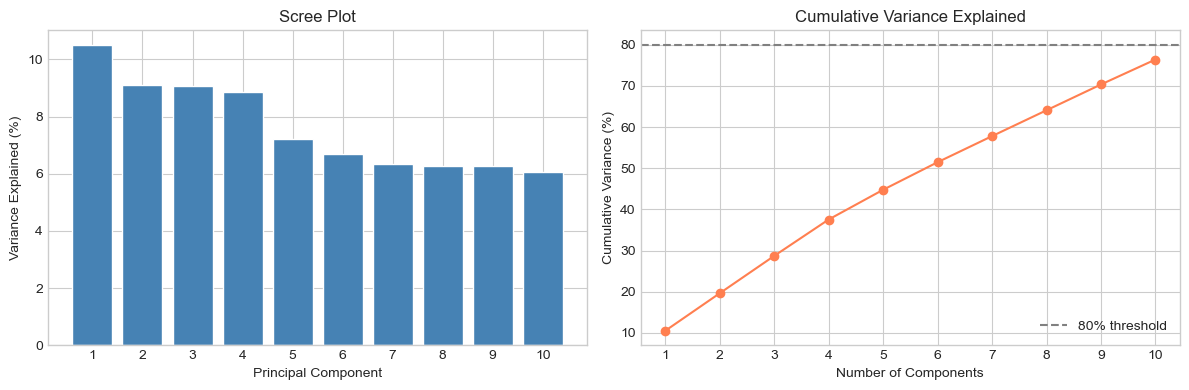

In [20]:
cumvar = np.cumsum(pca_full.explained_variance_ratio_)

variance_table = pd.DataFrame({
    'n_components': range(1, len(cumvar) + 1),
    'Incremental Variance (%)': (pca_full.explained_variance_ratio_ * 100).round(2),
    'Cumulative Variance (%)':  (cumvar * 100).round(2)
})
print('Variance explained by number of components:')
print(variance_table[variance_table['n_components'] <= 10].to_string(index=False))

# Scree plot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
k_range = range(2, min(11, len(cumvar) + 1))

axes[0].bar(range(1, len(pca_full.explained_variance_ratio_[:10]) + 1),
            pca_full.explained_variance_ratio_[:10] * 100,
            color='steelblue', edgecolor='white')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Variance Explained (%)')
axes[0].set_title('Scree Plot')
axes[0].set_xticks(range(1, 11))

axes[1].plot(range(1, len(cumvar[:10]) + 1), cumvar[:10] * 100,
             marker='o', color='coral')
axes[1].axhline(80, linestyle='--', color='gray', label='80% threshold')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Variance (%)')
axes[1].set_title('Cumulative Variance Explained')
axes[1].set_xticks(range(1, 11))
axes[1].legend()

plt.tight_layout()
plt.show()

**Answer:**

| Components | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|
| Cumulative variance | 19.6% | 28.7% | 37.5% | 44.8% | 51.5% | 57.8% | 64.1% | 70.4% | 76.4% |

Variance is spread unusually evenly: PC1 explains only 10.5%, and each of the first ten components adds 6–10%. There is no clear elbow. This is typical of a feature set made mostly of weakly correlated binary indicators — there is little shared structure for PCA to compress, so 2 components retain under 20% of the information.

**3. Set the number of components to 2. Which features load together with high weight in each component? Make sure to explore each component individually. (5 points)**

Feature loadings on PC1 and PC2:
                           PC1       PC2
exp_Internship        0.406542  0.405942
work_type_Internship  0.392658  0.395529
has_salary            0.342576 -0.133156
exp_Entry_level       0.329086 -0.216115
med_salary            0.232414 -0.102780
work_type_Part_time   0.150140 -0.054535
exp_Associate         0.100569 -0.339402
desc_word_count       0.088148  0.390445
work_type_Temporary   0.040996 -0.002002
skills_count          0.035264 -0.054472
work_type_Other       0.001739 -0.011732
work_type_Volunteer   0.000290 -0.015227
is_remote            -0.135672  0.011939
work_type_Contract   -0.234359 -0.319328
is_senior            -0.279822  0.359386
exp_Mid_Senior_level -0.453747  0.313913


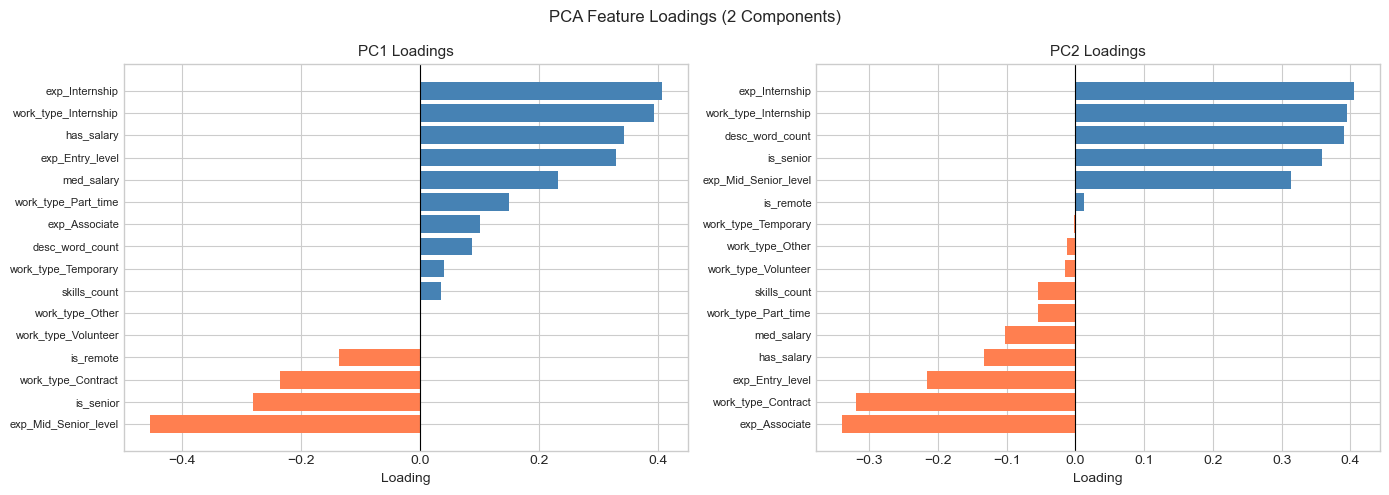

In [21]:
# Fit 2-component PCA
pca2 = PCA(n_components=2, random_state=SEED)
X_pca2 = pca2.fit_transform(X_std_all)

# Loading matrix
loadings = pd.DataFrame(
    pca2.components_.T,
    index=FEATURES,
    columns=['PC1', 'PC2']
)
print('Feature loadings on PC1 and PC2:')
print(loadings.sort_values('PC1', ascending=False).to_string())

# Biplot of loadings
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, pc in zip(axes, ['PC1', 'PC2']):
    sorted_load = loadings[pc].sort_values()
    colors = ['steelblue' if v >= 0 else 'coral' for v in sorted_load]
    ax.barh(sorted_load.index, sorted_load.values, color=colors)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'{pc} Loadings', fontsize=11)
    ax.set_xlabel('Loading')
    ax.tick_params(axis='y', labelsize=8)

plt.suptitle('PCA Feature Loadings (2 Components)', fontsize=12)
plt.tight_layout()
plt.show()

**Answer:**

**PC1 — "early-career vs. mid-senior" axis (10.5% of variance).** Large positive loadings on `exp_Internship` (0.41), `work_type_Internship` (0.39), `has_salary` (0.34), `exp_Entry_level` (0.33) and `med_salary` (0.23); large negative loadings on `exp_Mid_Senior_level` (−0.45), `is_senior` (−0.28) and `work_type_Contract` (−0.23). High PC1 scores are internship/entry-level postings that more often disclose pay; low scores are senior and contract roles.

**PC2 — "internship & long description vs. associate/contract" axis (9.1%).** Positive loadings on `exp_Internship` (0.41), `work_type_Internship` (0.40), `desc_word_count` (0.39), `is_senior` (0.36) and `exp_Mid_Senior_level` (0.31); negative on `exp_Associate` (−0.34) and `work_type_Contract` (−0.32). It separates full-time postings with long descriptions from shorter associate-level and contract postings.

Notably, `is_remote` — the feature most correlated with the label — loads weakly on both components (−0.14, 0.01).

**4. Using the best overall performing model (from Part 3, Q4), execute the same model. This time, use the same label, but replace the features with the two principle components. (5 points)**

*report the accuracy score and cohen kappa*

In [22]:
# Use 2 PCA components as features with the best model from Part 3
print(f'Best model: {BEST_MODEL_NAME}')

X_pca_tr, X_pca_te, y_pca_tr, y_pca_te = train_test_split(
    X_pca2, y, test_size=0.20, random_state=SEED
)

BEST_MODEL.fit(X_pca_tr, y_pca_tr)
y_pca_pred = BEST_MODEL.predict(X_pca_te)

pca_acc   = accuracy_score(y_pca_te, y_pca_pred)
pca_kappa = cohen_kappa_score(y_pca_te, y_pca_pred)

print(f'\n{BEST_MODEL_NAME} with 2 PCA components:')
print(f'  Accuracy:     {pca_acc:.4f}')
print(f"  Cohen's Kappa: {pca_kappa:.4f}")

# Compare to best model performance with all features
best_all_acc   = acc_table.loc[BEST_MODEL_NAME].max()
best_all_kappa = kappa_table.loc[BEST_MODEL_NAME].max()
print(f'\nComparison:')
print(f'  All features — best accuracy: {best_all_acc:.4f},  best kappa: {best_all_kappa:.4f}')
print(f'  2 PCA comps  — accuracy:      {pca_acc:.4f},  kappa:      {pca_kappa:.4f}')
print(f'  Accuracy difference: {pca_acc - best_all_acc:+.4f}')

Best model: SVM

SVM with 2 PCA components:
  Accuracy:     0.5142
  Cohen's Kappa: -0.0025

Comparison:
  All features — best accuracy: 0.6118,  best kappa: 0.2254
  2 PCA comps  — accuracy:      0.5142,  kappa:      -0.0025
  Accuracy difference: -0.0976


**5. How did the model accuracy using the two principal components compare to the model using all of the features? (5 points)**

**Answer:**

Using only the first two principal components, the SVM **drops from 61.2% to 51.4% accuracy, and Cohen's κ falls from 0.225 to −0.003** — no better than chance.

1. **Information loss:** the two components retain only 19.6% of feature variance.
2. **PCA ignores the label:** the components capture the experience-level / internship structure of the postings, while the most predictive feature, `is_remote`, barely loads on either component. The variance PCA keeps is not the variance that predicts applicant volume.
3. **Few features to begin with:** with only 16 features there is no curse of dimensionality to offset, so compression costs accuracy without any regularization benefit.

Lesson: unsupervised dimensionality reduction should be validated against the downstream task; here, supervised feature selection (the top-5 subset) preserved accuracy far better than PCA.

**6. Tune a K-means cluster model on this dataset, using the standardized features. In particular, tune the number of clusters *K* to a level that, in your best judgment, produces representative clusters and appropriate complexity (5 points)**

  K= 2: inertia = 343739.76
  K= 3: inertia = 315908.64
  K= 4: inertia = 290722.78
  K= 5: inertia = 269238.51
  K= 6: inertia = 245924.39
  K= 7: inertia = 220977.14
  K= 8: inertia = 200998.17
  K= 9: inertia = 180053.23
  K=10: inertia = 157210.92
  K=11: inertia = 140122.39


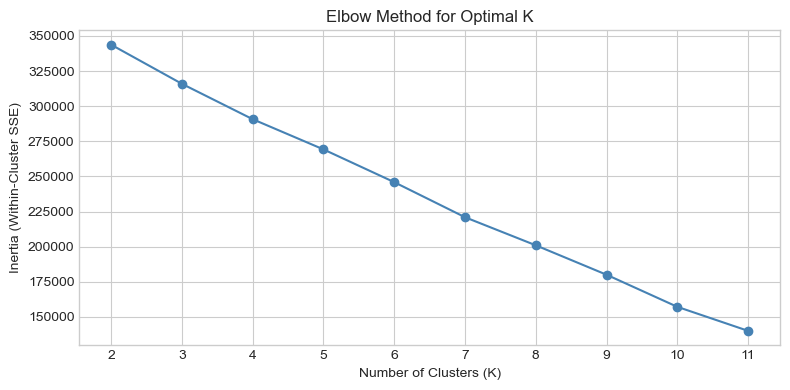

  K= 2: silhouette = 0.4864
  K= 3: silhouette = 0.1565
  K= 4: silhouette = 0.2095
  K= 5: silhouette = 0.2207
  K= 6: silhouette = 0.2387
  K= 7: silhouette = 0.2874
  K= 8: silhouette = 0.2876
  K= 9: silhouette = 0.2723
  K=10: silhouette = 0.3069
  K=11: silhouette = 0.2987


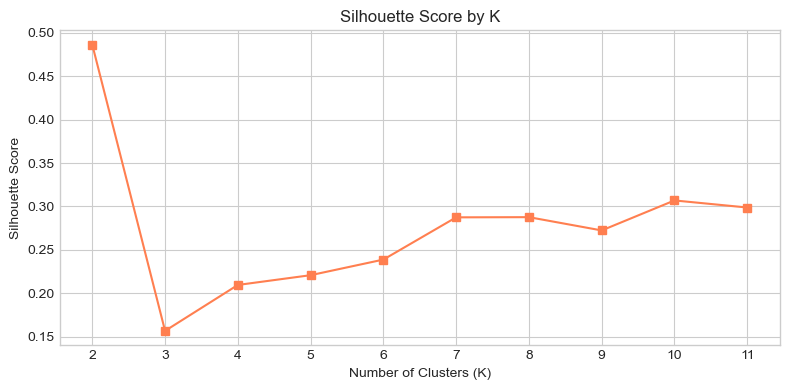


Selected K = 2 (highest silhouette score)


In [23]:
# Elbow method to choose optimal K
inertias = []
k_range = range(2, 12)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    km.fit(X_std_all)
    inertias.append(km.inertia_)
    print(f'  K={k:2d}: inertia = {km.inertia_:.2f}')

# Elbow plot
plt.figure(figsize=(8, 4))
plt.plot(k_range, inertias, marker='o', color='steelblue')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia (Within-Cluster SSE)')
plt.title('Elbow Method for Optimal K')
plt.xticks(k_range)
plt.tight_layout()
plt.show()

# Silhouette scores for additional guidance
from sklearn.metrics import silhouette_score
silhouettes = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = km.fit_predict(X_std_all)
    sil = silhouette_score(X_std_all, labels, sample_size=5000, random_state=SEED)
    silhouettes.append(sil)
    print(f'  K={k:2d}: silhouette = {sil:.4f}')

plt.figure(figsize=(8, 4))
plt.plot(k_range, silhouettes, marker='s', color='coral')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score by K')
plt.xticks(k_range)
plt.tight_layout()
plt.show()

OPTIMAL_K = k_range[np.argmax(silhouettes)]
print(f'\nSelected K = {OPTIMAL_K} (highest silhouette score)')

**7. Fit the model (5 points)**

In [24]:
# Fit the final K-means model with selected K
kmeans_final = KMeans(n_clusters=OPTIMAL_K, random_state=SEED, n_init=10)
cluster_labels = kmeans_final.fit_predict(X_std_all)

df_cluster = df_std[FEATURES + [LABEL]].copy()
df_cluster['cluster'] = cluster_labels
df_cluster['PC1'] = X_pca2[:, 0]
df_cluster['PC2'] = X_pca2[:, 1]

print(f'K-means model fitted with K={OPTIMAL_K} clusters.')
print(f'\nCluster size distribution:')
print(df_cluster['cluster'].value_counts().sort_index().to_string())
print(f'\nInertia: {kmeans_final.inertia_:.2f}')

K-means model fitted with K=2 clusters.

Cluster size distribution:
cluster
0    22381
1      939

Inertia: 343739.76


**8. Calculate cluster statistics to see how they are differentiated from each other (5 points)**

Cluster means (original scale):
cluster                     0          1
med_salary              0.000  33166.954
has_salary              0.000      1.000
is_remote               0.276      0.249
desc_word_count       470.629    463.775
skills_count            0.053      0.092
is_senior               0.208      0.100
work_type_Contract      0.197      0.223
work_type_Internship    0.014      0.059
work_type_Other         0.003      0.000
work_type_Part_time     0.027      0.072
work_type_Temporary     0.005      0.014
work_type_Volunteer     0.001      0.001
exp_Associate           0.124      0.153
exp_Entry_level         0.144      0.257
exp_Internship          0.013      0.050
exp_Mid_Senior_level    0.376      0.250
high_applies            0.522      0.494


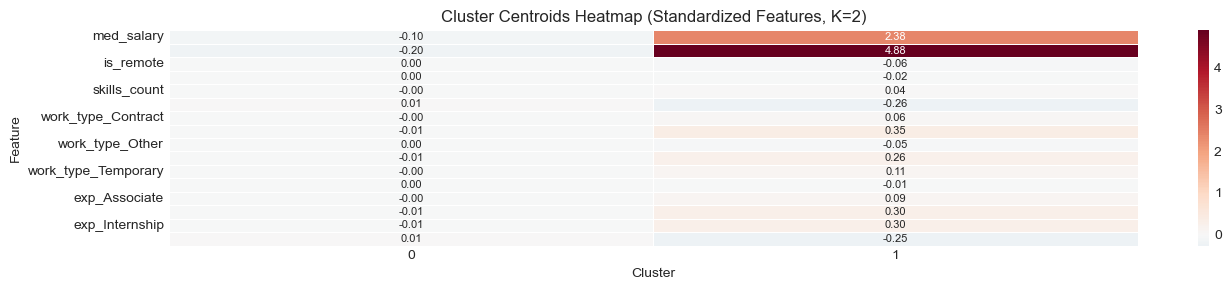


Proportion of high_applies=1 per cluster:
cluster
0    0.522
1    0.494


In [25]:
# Cluster means on original (un-standardized) scale for interpretability
df_cluster_raw = df_model[FEATURES + [LABEL]].copy()
df_cluster_raw['cluster'] = cluster_labels

cluster_stats = df_cluster_raw.groupby('cluster')[FEATURES + [LABEL]].agg(['mean', 'std'])

# Cluster means (readable table)
cluster_means = df_cluster_raw.groupby('cluster')[FEATURES + [LABEL]].mean().round(3)
print('Cluster means (original scale):')
print(cluster_means.T.to_string())

# Heatmap of cluster means (standardized)
cluster_means_std = df_cluster[FEATURES + [LABEL]].copy()
cluster_means_std['cluster'] = cluster_labels
heatmap_data = cluster_means_std.groupby('cluster')[FEATURES].mean()

plt.figure(figsize=(14, max(3, OPTIMAL_K * 0.7)))
sns.heatmap(
    heatmap_data.T, annot=True, fmt='.2f', cmap='RdBu_r',
    center=0, linewidths=0.5, annot_kws={'size': 8}
)
plt.title(f'Cluster Centroids Heatmap (Standardized Features, K={OPTIMAL_K})')
plt.ylabel('Feature')
plt.xlabel('Cluster')
plt.tight_layout()
plt.show()

# Label distribution per cluster
print('\nProportion of high_applies=1 per cluster:')
print(df_cluster_raw.groupby('cluster')[LABEL].mean().round(3).to_string())

**9. Visualize the clusters -- make sure the binary indicator you created for your label is colored differently (5 points)**

HINT: I want to see if your clusters are **really** differentiating

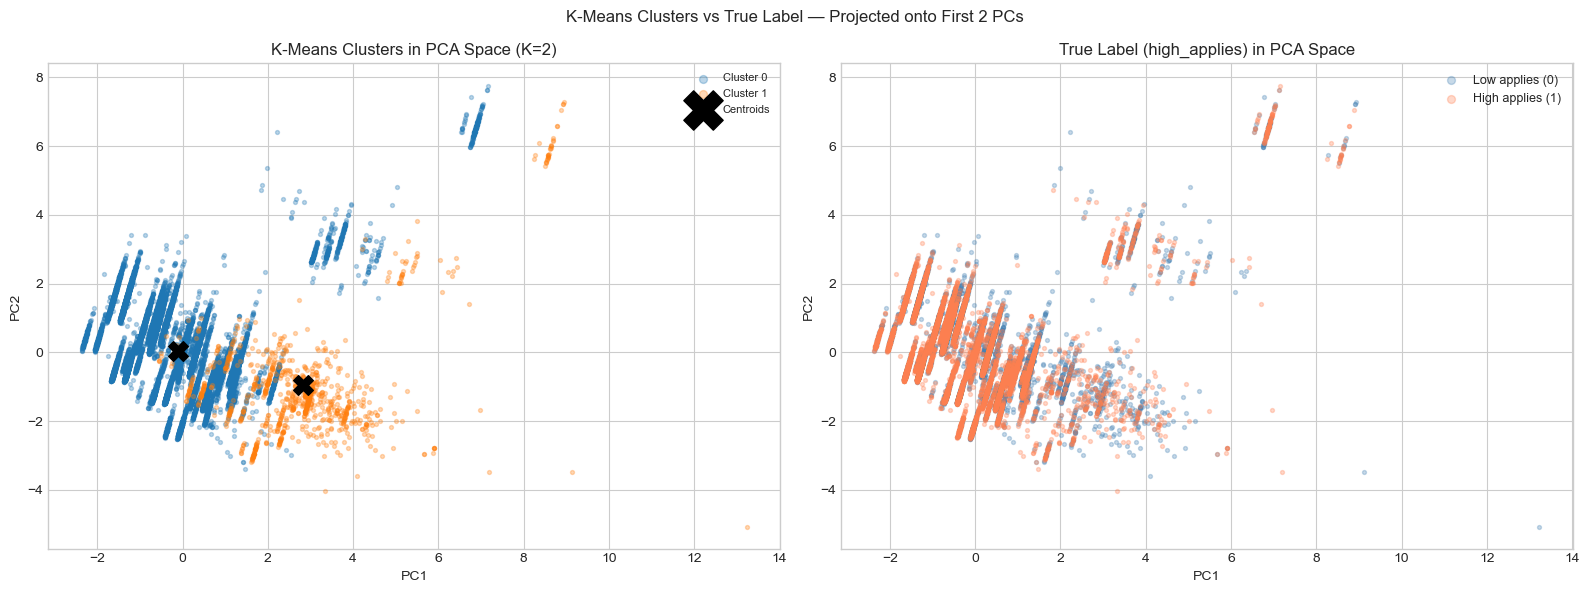


Cross-tabulation: Cluster assignment vs True Label (high_applies):
high_applies      0      1
Cluster                   
0             0.478  0.522
1             0.506  0.494
All           0.479  0.521


In [26]:
# Plot 1: Clusters in PCA space (colored by cluster assignment)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cluster_palette = sns.color_palette('tab10', OPTIMAL_K)

# Panel 1: color by cluster
for c in range(OPTIMAL_K):
    mask = df_cluster['cluster'] == c
    axes[0].scatter(
        df_cluster.loc[mask, 'PC1'],
        df_cluster.loc[mask, 'PC2'],
        s=8, alpha=0.3, label=f'Cluster {c}',
        color=cluster_palette[c]
    )
# Cluster centroids
centroids_2d = pca2.transform(kmeans_final.cluster_centers_)
axes[0].scatter(
    centroids_2d[:, 0], centroids_2d[:, 1],
    s=200, marker='X', color='black', zorder=5, label='Centroids'
)
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].set_title(f'K-Means Clusters in PCA Space (K={OPTIMAL_K})')
axes[0].legend(markerscale=2, fontsize=8)

# Panel 2: color by high_applies label (0=low, 1=high)
label_colors = {0: 'steelblue', 1: 'coral'}
label_names  = {0: 'Low applies (0)', 1: 'High applies (1)'}
for lv in [0, 1]:
    mask = df_cluster[LABEL] == lv
    axes[1].scatter(
        df_cluster.loc[mask, 'PC1'],
        df_cluster.loc[mask, 'PC2'],
        s=8, alpha=0.3, label=label_names[lv],
        color=label_colors[lv]
    )
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].set_title('True Label (high_applies) in PCA Space')
axes[1].legend(markerscale=2, fontsize=9)

plt.suptitle('K-Means Clusters vs True Label — Projected onto First 2 PCs', fontsize=12)
plt.tight_layout()
plt.show()

# Cross-tabulation: cluster assignments vs true label
print('\nCross-tabulation: Cluster assignment vs True Label (high_applies):')
crosstab = pd.crosstab(
    df_cluster['cluster'], df_cluster[LABEL],
    rownames=['Cluster'], colnames=['high_applies'],
    margins=True, normalize='index'
).round(3)
print(crosstab.to_string())

**Answer (K-means):**

Silhouette scores peak at **K = 2 (0.49)**; all other K are ≤ 0.31, so K = 2 was selected. The two clusters are very unbalanced (22,381 vs. 939 postings) and are almost entirely defined by **salary disclosure**: every posting in cluster 1 discloses a salary (mean $33k) and none in cluster 0 does. Cluster 1 also skews toward entry-level, internship and part-time roles.

**The clusters do not differentiate applicant volume**: the high-applies share is 52.2% in cluster 0 vs. 49.4% in cluster 1, essentially the base rate of 52.1%. Like PCA, K-means recovers the dominant structure among the features (who discloses pay), which is unrelated to the outcome.

---
## Summary of findings

1. **Remote eligibility is the strongest single signal** of high applicant volume (r = 0.20); contract roles also draw more applicants (r = 0.12), while entry-level postings and longer descriptions draw fewer.
2. **Salary disclosure does not predict applicant volume** in this data (r = −0.01), contrary to our hypothesis. Only 4% of postings with recorded applies disclose a median salary.
3. **The best classifiers reach ~61% accuracy (κ ≈ 0.22)**: SVM, AdaBoost, logistic regression and a depth-limited decision tree are statistically indistinguishable. Unpruned trees and Random Forest overfit (~54%).
4. **Unsupervised structure is orthogonal to the outcome.** Two principal components (19.6% of variance) reduce the SVM to chance level, and K-means splits postings by salary disclosure, not by applicant volume.

**Implication:** posting metadata explains only a small share of applicant volume. Employer brand, job title, location and posting promotion — absent from these features — are the likely drivers and the natural next step for analysis.